# Customer Churn — Interpretable Drivers and PCA Behavioural Axes

**Group:** Pinninti Sai Anish · Paravasthu Vamsi Krishna Suri · Kola Karan

**Research question.** *Can an interpretable supervised model identify churn drivers, and does PCA reveal independent behavioural axes?*

**Data.** IBM Telco Customer Churn sample (7,043 customers × 21 columns): tenure, monthly/total charges, contract, billing, demographics and service indicators; target `Churn` (Yes/No).

| § | Content |
|---|---|
| 0 | Setup — fixed seeds, configuration, experiment log |
| 1 | Data inspection — structure, target balance, missing values, leakage audit |
| 2 | Hypotheses (stated **before** training) |
| 3 | Fixed evaluation protocol + reproducible preprocessing pipelines (two encodings) |
| 4 | **Experiment 1** — Logistic Regression vs Random Forest (ROC-AUC, PR-AUC, churn recall) |
| 5 | **Experiment 2** — two legitimate categorical encodings, test set untouched; interpretability |
| 6 | **Experiment 3** — PCA without labels: components, robustness, original vs reduced predictors |
| 7 | Experiment log, hypothesis verdicts, interpretation |
| 8 | Oral-defense parameter changes |
| 9 | **MLflow tracking** — every configuration of Experiments 1–3 as a tracked run |
| 10 | **Model selection + registry** — champion chosen by CV, registered, MLflow UI |
| 11 | **Prediction API** — FastAPI service for the champion, called and tested from the notebook |
| 12 | **Streamlit website** — a churn risk desk on top of the API, with its own tests |
| 13 | **Docker image** — the champion, API and website packaged as one shareable image |

Run with `Runtime → Run all` in Google Colab, or `Kernel → Restart & Run All` locally (≈ 3 min). Every random component is driven by `SEED`.

**Colab setup.** The cell below installs what §9–§11 need (Colab already ships numpy, pandas, scikit-learn and matplotlib). If Colab shows *"restart session"* after it, restart and choose `Run all` again — the second time the install is instant.

In [1]:
%pip install -q "mlflow>=3.1" skops fastapi "uvicorn[standard]" requests "streamlit>=1.45"

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ============================================================================
# Customer Churn — Interpretable Drivers and PCA Behavioural Axes
# Authors: Pinninti Sai Anish, Paravasthu Vamsi Krishna Suri, Kola Karan
#   Pinninti Sai Anish             data inspection, leakage audit, protocol & pipelines
#   Paravasthu Vamsi Krishna Suri  Experiment 1 (LR vs RF) and Experiment 2 (encodings)
#   Kola Karan                     Experiment 3 (PCA)
# ============================================================================
# 0. SETUP — imports, global seed, configuration
# ============================================================================
import os, json, random, platform, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Reproducibility: ONE seed drives every random component -----------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# ---- Configuration (change here, nowhere else) -------------------------------
TEST_SIZE      = 0.20     # stratified hold-out, touched once per reported configuration
CV_FOLDS       = 5        # stratified CV inside the training set (all comparisons)
THRESHOLD      = 0.50     # decision threshold for recall / precision
LR_C           = 1.0      # inverse L2 strength
RF_TREES       = 500
RF_MIN_LEAF    = 10       # fixed a priori to limit overfitting; no tuning on test
PCA_VAR_TARGET = 0.90     # "reduced" representation = fewest PCs reaching 90 % variance
N_BOOT         = 200      # bootstrap refits (coefficient CIs, PCA loading stability)

ROOT = Path(".").resolve()
DATA_DIR, FIG_DIR, RES_DIR = ROOT / "data", ROOT / "figures", ROOT / "results"
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    d.mkdir(exist_ok=True)
DATA_PATH  = DATA_DIR / "telco_churn.csv"
SOURCE_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
              "master/data/Telco-Customer-Churn.csv")       # IBM's public copy (fallback only)

# ---- Figure style: thin marks, recessive grid, fixed colour roles -------------
C = {"lr": "#2a78d6", "rf": "#eb6834", "aqua": "#1baf7a", "violet": "#6250d6",
     "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.edgecolor": C["ink2"], "axes.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "legend.frameon": False, "lines.linewidth": 2,
})

def savefig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    print(f"saved → {path.relative_to(ROOT)}")

# ---- Experiment log: every reported number is appended here, saved to CSV -----
EXPERIMENT_LOG = []
def log_experiment(exp_id, model, config, split, metrics):
    row = {"exp_id": exp_id, "seed": SEED, "model": model,
           "config": json.dumps(config, sort_keys=True), "split": split}
    for k, v in metrics.items():
        row[k] = round(float(v), 4) if isinstance(v, (int, float, np.integer, np.floating)) else v
    EXPERIMENT_LOG.append(row)

print(f"python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | SEED={SEED}")

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2 | SEED=42


## 1. Data inspection
*Owner: Pinninti Sai Anish*
The loader validates the schema (columns present, allowed category values, numeric ranges) so a wrong or corrupted file fails loudly instead of silently producing results.

In [3]:
TARGET = "Churn"
ID_COL = "customerID"
NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
BINARY_YN = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
SERVICES = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]
NOMINAL = ["InternetService", "PaymentMethod"]
CAT = ["gender", "SeniorCitizen"] + BINARY_YN + SERVICES + NOMINAL + ["Contract"]
PREDICTORS = NUM + CAT                                    # 19 business variables

ALLOWED = {
    "gender": {"Female", "Male"}, "SeniorCitizen": {"0", "1"},
    **{c: {"Yes", "No"} for c in BINARY_YN},
    "MultipleLines": {"Yes", "No", "No phone service"},
    **{c: {"Yes", "No", "No internet service"} for c in SERVICES[1:]},
    "InternetService": {"DSL", "Fiber optic", "No"},
    "PaymentMethod": {"Electronic check", "Mailed check", "Bank transfer (automatic)",
                      "Credit card (automatic)"},
    "Contract": {"Month-to-month", "One year", "Two year"},
}

def load_telco(path=DATA_PATH):
    if not path.exists():
        import urllib.request
        urllib.request.urlretrieve(SOURCE_URL, path)
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)        # read as text, then validate
    missing = set(PREDICTORS + [TARGET, ID_COL]) - set(raw.columns)
    assert not missing, f"missing columns: {missing}"
    df = raw[[ID_COL] + PREDICTORS + [TARGET]].copy()
    for c in CAT + [TARGET, ID_COL]:
        df[c] = df[c].astype(object).str.strip()
    bad = {c: set(df[c]) - ALLOWED[c] for c in CAT if set(df[c]) - ALLOWED[c]}
    assert not bad, f"unexpected category values: {bad}"
    assert set(df[TARGET]) <= {"Yes", "No"}, "target must be Yes/No"
    for c in NUM:                      # blank/space-only strings become NaN, anything else non-numeric fails
        df[c] = pd.to_numeric(df[c].astype(object).str.strip().replace("", np.nan), errors="raise").astype(float)
    assert (df[NUM].dropna() >= 0).all().all(), "negative numeric values"
    df[TARGET] = (df[TARGET] == "Yes").astype(int)
    return df

df = load_telco()
print("shape:", df.shape)
df.head(3)

shape: (7043, 21)


,customerID,tenure,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,PaperlessBilling,...,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetService,PaymentMethod,Contract,Churn
0,7590-VHVEG,1.0,29.85,29.85,Female,0,Yes,No,No,Yes,...,No,Yes,No,No,No,No,DSL,Electronic check,Month-to-month,0
1,5575-GNVDE,34.0,56.95,1889.50,Male,0,No,No,Yes,No,...,Yes,No,Yes,No,No,No,DSL,Mailed check,One year,0
2,3668-QPYBK,2.0,53.85,108.15,Male,0,No,No,Yes,Yes,...,Yes,Yes,No,No,No,No,DSL,Mailed check,Month-to-month,1


In [4]:
# ---- 1a. Missing values and the TotalCharges blanks -----------------------------
na = df.isna().sum()
print("missing values:", na[na > 0].to_dict())
blank = df[df["TotalCharges"].isna()]
print(f"rows with blank TotalCharges: {len(blank)} — tenure values: {sorted(blank.tenure.unique())}, "
      f"churners among them: {blank[TARGET].sum()}")
# Domain rule (row-wise, uses no dataset statistics → leakage-free): a customer with
# tenure 0 has not been billed yet, so TotalCharges = 0. A median imputer would give them ≈ 1,400.
assert (blank["tenure"] == 0).all()
df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0.0
assert df["TotalCharges"].notna().all()

print(f"duplicated customerID: {df[ID_COL].duplicated().sum()} | identical predictor rows "
      f"(different customers): {df.duplicated(subset=PREDICTORS).sum()}")
df[NUM].describe().T.round(2)

missing values: {'TotalCharges': 11}
rows with blank TotalCharges: 11 — tenure values: [np.float64(0.0)], churners among them: 0
duplicated customerID: 0 | identical predictor rows (different customers): 40


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


churn rate 26.5%  → 'never churns' rule scores accuracy 73.5% with churn recall 0
saved → figures/fig1_target_and_contract.png


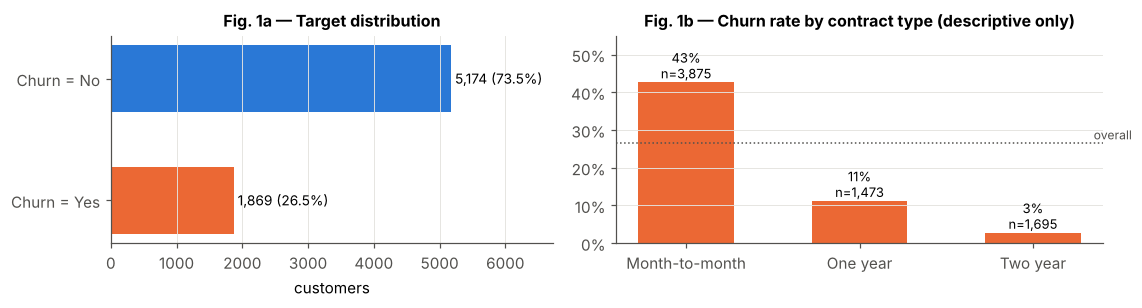

In [5]:
# ---- 1b. Target distribution + churn by contract  →  Figure 1 --------------------
prev = df[TARGET].mean()
print(f"churn rate {prev:.1%}  → 'never churns' rule scores accuracy {1 - prev:.1%} with churn recall 0")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 2.9), gridspec_kw={"width_ratios": [1, 1.1]})
cnt = df[TARGET].value_counts().sort_index()
bars = ax1.barh(["Churn = Yes", "Churn = No"], [cnt[1], cnt[0]], color=[C["rf"], C["lr"]], height=0.55)
for b, v in zip(bars, [cnt[1], cnt[0]]):
    ax1.text(v + 60, b.get_y() + b.get_height() / 2, f"{v:,} ({v / len(df):.1%})", va="center", fontsize=9)
ax1.set_xlim(0, cnt.max() * 1.3); ax1.grid(axis="y", visible=False); ax1.set_xlabel("customers")
ax1.set_title("Fig. 1a — Target distribution")

by = df.groupby("Contract")[TARGET].agg(["mean", "size"]).loc[["Month-to-month", "One year", "Two year"]]
b2 = ax2.bar(by.index, by["mean"], color=C["rf"], width=0.55)
for b, (_, r) in zip(b2, by.iterrows()):
    ax2.text(b.get_x() + b.get_width() / 2, r["mean"] + 0.01, f"{r['mean']:.0%}\nn={int(r['size']):,}",
             ha="center", fontsize=8.5)
ax2.axhline(prev, color=C["ink2"], ls=":", lw=1); ax2.text(2.35, prev + 0.01, "overall", fontsize=8, color=C["ink2"])
ax2.yaxis.set_major_formatter(PercentFormatter(1)); ax2.set_ylim(0, 0.55); ax2.grid(axis="x", visible=False)
ax2.set_title("Fig. 1b — Churn rate by contract type (descriptive only)")
fig.tight_layout(); savefig(fig, "fig1_target_and_contract"); plt.show()

In [6]:
# ---- 1c. Leakage and redundancy audit ---------------------------------------------
approx = df["tenure"] * df["MonthlyCharges"]
r_tc = np.corrcoef(approx, df["TotalCharges"])[0, 1]
print(f"corr(TotalCharges, tenure × MonthlyCharges) = {r_tc:.3f}  → TotalCharges is (almost) derived")
print(f"corr(tenure, TotalCharges) = {df['tenure'].corr(df['TotalCharges']):.3f}")
no_int = df["InternetService"] == "No"
same = all((df.loc[no_int, c] == "No internet service").all() for c in SERVICES[1:])
print(f"'No internet service' appears in all 6 add-on columns exactly when InternetService == 'No': {same}"
      "  → structural duplication of one fact across 7 columns")

corr(TotalCharges, tenure × MonthlyCharges) = 1.000  → TotalCharges is (almost) derived
corr(tenure, TotalCharges) = 0.826
'No internet service' appears in all 6 add-on columns exactly when InternetService == 'No': True  → structural duplication of one fact across 7 columns


**Leakage audit — conclusions that shape the protocol**

| Risk | Finding | Decision |
|---|---|---|
| Identifier | `customerID` is unique per row; carries no signal, but a model could memorise it | dropped from predictors |
| Target leakage | no column is a consequence of churning (no "cancellation date", "retention offer"…) | all 19 business variables allowed |
| Temporal leakage | the data is a single snapshot: for churners, `tenure`/`TotalCharges` are *final* values measured at departure | cannot be fixed here → stated as a limitation; affects deployment, not the in-sample comparison |
| Derived features | `TotalCharges ≈ tenure × MonthlyCharges` (r ≈ 0.99 with the product) | kept, but LR coefficients of the three numerics are read jointly, not individually |
| Preprocessing leakage | imputers/encoders/scalers/PCA fitted on all rows would see the test set | everything lives in one `Pipeline`, refitted inside every CV fold; test set only ever passed to `predict` |
| Structural duplication | "No internet service" repeated in 6 columns + `InternetService=No` | motivates Experiment 2 (compact encoding) |

## 2. Hypotheses (fixed before any model is trained)

- **H1 — Interpretable is enough.** Logistic Regression will reach a test ROC-AUC **within 0.02 of, or above,** the Random Forest, because the dominant drivers (contract, tenure, charges, internet type) act mostly monotonically. Both models will have **churn recall < 0.60 at threshold 0.5**, so recall must be read together with precision/PR-AUC.
- **H2 — Independent behavioural axes.** Fitted without labels, **PC1 and PC2 will load on different business variables** (a *tenure / commitment* axis vs a *service-breadth / spend* axis, i.e. different top-3 loading variables). A **2-PC representation will lose ≥ 0.03 ROC-AUC** versus the original predictors (LR), whereas the representation reaching 90 % variance will be within 0.01.

## 3. Fixed evaluation protocol and preprocessing pipelines
*Owner: Pinninti Sai Anish*

| Step | Decision | Why |
|---|---|---|
| Split | stratified 80 / 20 train/test, `random_state=SEED`; test set **used once per reported configuration**, never for choices | unbiased final estimate |
| Comparisons | stratified 5-fold CV on the training set; **identical frozen folds** for every model/encoding | paired, fair comparisons with mean ± SD |
| Preprocessing | encoding → `StandardScaler` (all columns) inside a `Pipeline` | standardised LR coefficients are comparable per SD; PCA requires common scale |
| Hyper-parameters | fixed a priori (LR `C=1`, RF 500 trees, `min_samples_leaf=10`) | no tuning loop to leak into the test set |
| Metrics | **ROC-AUC** (ranking), **PR-AUC** (ranking focused on churners, chance = 26.5 %), churn **recall** + precision at 0.5, MCC | accuracy is dominated by the 73.5 % non-churners |

**Encoding A — full one-hot.** Every category of the 16 categorical variables becomes its own 0/1 column (`OneHotEncoder`, no category dropped).
**Encoding B — compact business encoding.** Fixed, label-free domain rules: Yes/No → 1/0; service add-ons → 1 only if subscribed ("No internet/phone service" → 0, that fact already lives in `InternetService`); `Contract` → committed months (0 / 12 / 24) as one ordinal number; one-hot (first level dropped) only for the two truly nominal variables `InternetService`, `PaymentMethod`.
Both encodings use **no target information and no dataset statistics** in the mapping itself, so neither can leak.

In [7]:
# ---- 3a. Fixed split ----------------------------------------------------------------
X, y = df[PREDICTORS].copy(), df[TARGET].to_numpy()
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, df[ID_COL], test_size=TEST_SIZE, stratify=y, random_state=SEED)
assert set(id_train).isdisjoint(id_test)
assert abs(y_train.mean() - y_test.mean()) < 0.01
CV_SPLITS = list(StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train))
TEST_FINGERPRINT = pd.util.hash_pandas_object(X_test).sum()      # re-checked at the end: test untouched
print(f"train {len(y_train):,} (churn {y_train.mean():.1%}) | test {len(y_test):,} (churn {y_test.mean():.1%})")

train 5,634 (churn 26.5%) | test 1,409 (churn 26.5%)


In [8]:
# ---- 3b. Two legitimate encodings, each a full reproducible pipeline ---------------
CONTRACT_MONTHS = {"Month-to-month": 0, "One year": 12, "Two year": 24}

def compact_encode(frame):
    # Encoding B: fixed domain rules, applied row by row — no fitting, no labels.
    out = pd.DataFrame(index=frame.index)
    out[NUM] = frame[NUM].astype(float)
    out["gender_male"] = (frame["gender"] == "Male").astype(int)
    out["SeniorCitizen"] = frame["SeniorCitizen"].astype(int)
    for c in BINARY_YN + SERVICES:
        out[c] = (frame[c] == "Yes").astype(int)
    out["contract_months"] = frame["Contract"].map(CONTRACT_MONTHS)
    if out["contract_months"].isna().any():
        raise ValueError("unknown Contract value")
    out[NOMINAL] = frame[NOMINAL]
    return out

def make_prep(encoding):
    if encoding == "A_onehot":
        enc = ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), NUM),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)],
            verbose_feature_names_out=False)
        steps = [("encode", enc)]
    elif encoding == "B_compact":
        compact = FunctionTransformer(compact_encode)   # returns a DataFrame → column names kept
        compact.set_output(transform="pandas")
        nominal = ColumnTransformer([
            ("nom", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), NOMINAL)],
            remainder=SimpleImputer(strategy="median"), verbose_feature_names_out=False)
        steps = [("compact", compact), ("encode", nominal)]
    else:
        raise ValueError(encoding)
    return Pipeline(steps + [("scale", StandardScaler())]).set_output(transform="pandas")

def make_model(name, encoding="A_onehot", n_pcs=None):
    clf = (LogisticRegression(C=LR_C, max_iter=5000, random_state=SEED) if name == "LogReg" else
           RandomForestClassifier(n_estimators=RF_TREES, min_samples_leaf=RF_MIN_LEAF,
                                  max_features="sqrt", n_jobs=-1, random_state=SEED))
    steps = [("prep", make_prep(encoding))]
    if n_pcs is not None:
        steps.append(("pca", PCA(n_components=n_pcs, random_state=SEED)))
    return Pipeline(steps + [("clf", clf)])

for e in ("A_onehot", "B_compact"):
    Zt = make_prep(e).fit(X_train).transform(X_train.head(5))
    print(f"{e:10s} → {Zt.shape[1]} encoded columns, e.g. {list(Zt.columns[:6])} …")

A_onehot   → 46 encoded columns, e.g. ['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Female', 'gender_Male', 'SeniorCitizen_0'] …
B_compact  → 22 encoded columns, e.g. ['InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'tenure'] …


In [9]:
# ---- 3c. Evaluation helpers -----------------------------------------------------------
def metrics_at(y_true, proba, thr=THRESHOLD):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"roc_auc": roc_auc_score(y_true, proba), "pr_auc": average_precision_score(y_true, proba),
            "recall": recall_score(y_true, pred, zero_division=0),
            "precision": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0), "mcc": matthews_corrcoef(y_true, pred),
            "accuracy": accuracy_score(y_true, pred), "flagged_pct": pred.mean(),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}

def cross_validate_model(model):
    # frozen folds; every fold refits the WHOLE pipeline (encoder, scaler, PCA, classifier)
    rows, oof = [], np.zeros(len(y_train))
    for tr, va in CV_SPLITS:
        m = clone(model).fit(X_train.iloc[tr], y_train[tr])
        oof[va] = m.predict_proba(X_train.iloc[va])[:, 1]
        rows.append(metrics_at(y_train[va], oof[va]))
    return pd.DataFrame(rows), oof

def fit_and_test(model):
    fitted = clone(model).fit(X_train, y_train)
    return fitted, fitted.predict_proba(X_test)[:, 1]

ms = lambda s: f"{s.mean():.3f} ± {s.std():.3f}"

base = metrics_at(y_test, np.zeros(len(y_test)))
base["pr_auc"] = y_test.mean()
log_experiment("BASE", "NeverChurns", {}, "test", base)
print(f"majority baseline (test): accuracy {base['accuracy']:.3f}, churn recall {base['recall']:.0f}, "
      f"PR-AUC (chance) {base['pr_auc']:.3f}")

majority baseline (test): accuracy 0.735, churn recall 0, PR-AUC (chance) 0.265


## 4. Experiment 1 — baseline comparison: Logistic Regression vs Random Forest
*Owner: Paravasthu Vamsi Krishna Suri*
Encoding A (the standard one-hot), same folds, same threshold. ROC-AUC measures overall ranking; PR-AUC focuses on how clean the top of the ranking is for the minority class; recall answers *"what share of churners do we catch at 0.5?"*.

In [10]:
E1, rows = {}, []
for name in ["LogReg", "RandomForest"]:
    model = make_model(name, "A_onehot")
    folds, oof = cross_validate_model(model)
    fitted, proba = fit_and_test(model)
    t = metrics_at(y_test, proba)
    E1[name] = {"fitted": fitted, "proba": proba, "folds": folds, "oof": oof}
    cfg = {"encoding": "A_onehot", "threshold": THRESHOLD}
    log_experiment("E1", name, cfg, f"cv{CV_FOLDS}_mean", folds.mean().to_dict())
    log_experiment("E1", name, cfg, "test", t)
    rows.append({"model": name, "CV ROC-AUC": ms(folds.roc_auc), "CV PR-AUC": ms(folds.pr_auc),
                 "CV churn recall": ms(folds.recall), "test ROC-AUC": t["roc_auc"], "test PR-AUC": t["pr_auc"],
                 "test churn recall": t["recall"], "test precision": t["precision"], "test MCC": t["mcc"],
                 "test accuracy": t["accuracy"]})
TABLE1 = pd.DataFrame(rows).set_index("model")
TABLE1.loc["NeverChurns baseline"] = ["—"] * 3 + [0.5, base["pr_auc"], 0.0, 0.0, 0.0, base["accuracy"]]
TABLE1.to_csv(RES_DIR / "table1_exp1_baseline_comparison.csv")
TABLE1

,CV ROC-AUC,CV PR-AUC,CV churn recall,test ROC-AUC,test PR-AUC,test churn recall,test precision,test MCC,test accuracy
model,,,,,,,,,
LogReg,0.846 ± 0.014,0.661 ± 0.021,0.545 ± 0.047,0.841747,0.631236,0.566845,0.660436,0.485892,0.807665
RandomForest,0.848 ± 0.010,0.662 ± 0.022,0.491 ± 0.013,0.843979,0.654918,0.508021,0.678571,0.465939,0.805536
NeverChurns baseline,—,—,—,0.500000,0.265436,0.000000,0.000000,0.000000,0.734564


In [11]:
# Paired fold-wise difference (same folds → differences are meaningful)
d_auc = E1["LogReg"]["folds"].roc_auc - E1["RandomForest"]["folds"].roc_auc
d_pr = E1["LogReg"]["folds"].pr_auc - E1["RandomForest"]["folds"].pr_auc
print(f"LR − RF per fold: ROC-AUC {np.round(d_auc.values, 3)} (mean {d_auc.mean():+.3f}); "
      f"PR-AUC mean {d_pr.mean():+.3f}; LR wins {int((d_auc > 0).sum())}/{CV_FOLDS} folds on ROC-AUC")

# Why recall alone is not enough: the same LR model at several thresholds (test)
rows = []
for thr in [0.10, 0.20, 0.35, 0.50, 0.65]:
    m = metrics_at(y_test, E1["LogReg"]["proba"], thr)
    rows.append({"threshold": thr, "churn recall": m["recall"], "precision": m["precision"],
                 "customers flagged %": 100 * m["flagged_pct"], "false alarms": m["fp"], "missed churners": m["fn"]})
    log_experiment("E1-thr", "LogReg", {"encoding": "A_onehot", "threshold": thr}, "test", m)
TABLE1B = pd.DataFrame(rows).set_index("threshold")
TABLE1B.to_csv(RES_DIR / "table1b_recall_vs_threshold.csv")
TABLE1B.round(3)

LR − RF per fold: ROC-AUC [ 0.005 -0.01  -0.004  0.008 -0.007] (mean -0.001); PR-AUC mean -0.001; LR wins 2/5 folds on ROC-AUC


,churn recall,precision,customers flagged %,false alarms,missed churners
threshold,,,,,
0.10,0.947,0.406,61.817,517,20
0.20,0.856,0.466,48.687,366,54
0.35,0.709,0.544,34.564,222,109
0.50,0.567,0.660,22.782,109,162
0.65,0.307,0.747,10.930,39,259


saved → figures/fig2_exp1_lr_vs_rf.png


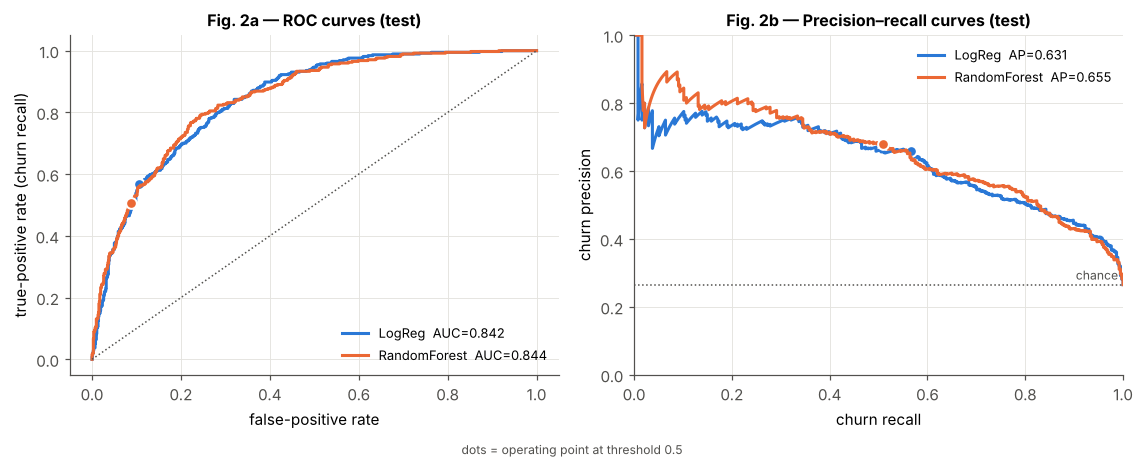

H1: LR within 0.02 ROC-AUC of RF → True; both recalls < 0.60 → True  ⇒ supported: True


In [12]:
# ---- Figure 2: supervised comparison — ROC and PR curves on the test set ------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4.1))
for name, col in (("LogReg", C["lr"]), ("RandomForest", C["rf"])):
    p = E1[name]["proba"]; m = metrics_at(y_test, p)
    fpr, tpr, _ = roc_curve(y_test, p)
    a1.plot(fpr, tpr, color=col, label=f"{name}  AUC={m['roc_auc']:.3f}")
    a1.plot(m["fp"] / (m["fp"] + m["tn"]), m["recall"], "o", ms=7, color=col, mec="white", mew=1.3)
    pr, rc, _ = precision_recall_curve(y_test, p)
    a2.plot(rc, pr, color=col, label=f"{name}  AP={m['pr_auc']:.3f}")
    a2.plot(m["recall"], m["precision"], "o", ms=7, color=col, mec="white", mew=1.3)
a1.plot([0, 1], [0, 1], color=C["ink2"], ls=":", lw=1)
a1.set(xlabel="false-positive rate", ylabel="true-positive rate (churn recall)", title="Fig. 2a — ROC curves (test)")
a2.axhline(y_test.mean(), color=C["ink2"], ls=":", lw=1); a2.text(0.99, y_test.mean() + 0.015, "chance", ha="right", fontsize=8, color=C["ink2"])
a2.set(xlabel="churn recall", ylabel="churn precision", xlim=(0, 1), ylim=(0, 1), title="Fig. 2b — Precision–recall curves (test)")
for a in (a1, a2):
    a.legend(loc="lower right" if a is a1 else "upper right", fontsize=8.5)
fig.text(0.5, -0.02, "dots = operating point at threshold 0.5", ha="center", fontsize=8, color=C["ink2"])
fig.tight_layout(); savefig(fig, "fig2_exp1_lr_vs_rf"); plt.show()

H1_auc_ok = E1["LogReg"]["folds"].roc_auc.mean() >= E1["RandomForest"]["folds"].roc_auc.mean() - 0.02 and \
            metrics_at(y_test, E1["LogReg"]["proba"])["roc_auc"] >= metrics_at(y_test, E1["RandomForest"]["proba"])["roc_auc"] - 0.02
H1_recall_ok = all(metrics_at(y_test, E1[n]["proba"])["recall"] < 0.60 for n in E1)
H1_SUPPORTED = bool(H1_auc_ok and H1_recall_ok)
print(f"H1: LR within 0.02 ROC-AUC of RF → {H1_auc_ok}; both recalls < 0.60 → {H1_recall_ok}  ⇒ supported: {H1_SUPPORTED}")

## 5. Experiment 2 — leakage-safe encoding comparison and interpretability
*Owner: Paravasthu Vamsi Krishna Suri*
Encodings A and B are compared **only by cross-validation on the training set**. The test set is scored once per configuration *after* the comparison is complete, purely for reporting; the fingerprint check below proves it was never modified or used for fitting.

In [13]:
E2, rows = {}, []
for enc in ["A_onehot", "B_compact"]:
    for name in ["LogReg", "RandomForest"]:
        model = make_model(name, enc)
        folds, _ = (E1[name]["folds"], None) if enc == "A_onehot" else cross_validate_model(model)
        fitted, proba = (E1[name]["fitted"], E1[name]["proba"]) if enc == "A_onehot" else fit_and_test(model)
        n_feat = fitted.named_steps["prep"].transform(X_train.head(1)).shape[1]   # encoded width
        t = metrics_at(y_test, proba)
        E2[(enc, name)] = {"fitted": fitted, "proba": proba, "folds": folds}
        cfg = {"encoding": enc, "threshold": THRESHOLD}
        if enc != "A_onehot":   # A was already logged in E1; avoid duplicate rows
            log_experiment("E2", name, cfg, f"cv{CV_FOLDS}_mean", folds.mean().to_dict())
            log_experiment("E2", name, cfg, "test", t)
        rows.append({"encoding": enc, "model": name, "n features": n_feat,
                     "CV ROC-AUC": ms(folds.roc_auc), "CV PR-AUC": ms(folds.pr_auc), "CV recall": ms(folds.recall),
                     "test ROC-AUC": t["roc_auc"], "test PR-AUC": t["pr_auc"], "test recall": t["recall"]})
TABLE2 = pd.DataFrame(rows).set_index(["encoding", "model"])
TABLE2.to_csv(RES_DIR / "table2_exp2_encodings.csv")
assert pd.util.hash_pandas_object(X_test).sum() == TEST_FINGERPRINT, "test set was modified!"
print("test-set fingerprint unchanged ✓")
TABLE2

test-set fingerprint unchanged ✓


n features     CV ROC-AUC      CV PR-AUC  \
encoding  model                                                    
A_onehot  LogReg                46  0.846 ± 0.014  0.661 ± 0.021   
          RandomForest          46  0.848 ± 0.010  0.662 ± 0.022   
B_compact LogReg                22  0.846 ± 0.014  0.662 ± 0.022   
          RandomForest          22  0.847 ± 0.011  0.664 ± 0.023   

                            CV recall  test ROC-AUC  test PR-AUC  test recall  
encoding  model                                                                
A_onehot  LogReg        0.545 ± 0.047      0.841747     0.631236     0.566845  
          RandomForest  0.491 ± 0.013      0.843979     0.654918     0.508021  
B_compact LogReg        0.544 ± 0.047      0.842104     0.632959     0.561497  
          RandomForest  0.490 ± 0.022      0.845951     0.657835     0.500000

In [14]:
# ---- Interpretability: LR coefficients under both encodings ---------------------------
def lr_coefs(fitted):
    names = fitted.named_steps["prep"].transform(X_train.head(1)).columns   # names from pandas output
    return pd.Series(fitted.named_steps["clf"].coef_[0], index=names)

coefA, coefB = lr_coefs(E2[("A_onehot", "LogReg")]["fitted"]), lr_coefs(E2[("B_compact", "LogReg")]["fitted"])
no_int_cols = [c for c in coefA.index if c.endswith("No internet service")] + ["InternetService_No"]
print("Encoding A — the single fact 'no internet' is spread over 7 identical columns, "
      "so L2 shares its weight among them:")
print(coefA[no_int_cols].round(3).to_string())
print(f"   → sum of the 7 coefficients = {coefA[no_int_cols].sum():+.3f}; any single one is not interpretable")
print("\nEncoding B — one coefficient per business fact (per +1 SD, log-odds):")
print(coefB.sort_values().round(3).to_string())

Encoding A — the single fact 'no internet' is spread over 7 identical columns, so L2 shares its weight among them:
OnlineSecurity_No internet service     -0.125
OnlineBackup_No internet service       -0.125
DeviceProtection_No internet service   -0.125
TechSupport_No internet service        -0.125
StreamingTV_No internet service        -0.125
StreamingMovies_No internet service    -0.125
InternetService_No                     -0.125
   → sum of the 7 coefficients = -0.876; any single one is not interpretable

Encoding B — one coefficient per business fact (per +1 SD, log-odds):
tenure                                  -1.268
MonthlyCharges                          -0.844
InternetService_No                      -0.621
contract_months                         -0.577
OnlineSecurity                          -0.130
TechSupport                             -0.107
Dependents                              -0.102
OnlineBackup                            -0.019
PaymentMethod_Credit card (automatic)  

In [15]:
# ---- Bootstrap CIs for encoding-B LR odds ratios (train only) ------------------------
rng = np.random.default_rng(SEED)
lrB = make_model("LogReg", "B_compact")
boot = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_train), len(y_train))
    boot.append(lr_coefs(clone(lrB).fit(X_train.iloc[idx], y_train[idx])))
boot = pd.DataFrame(boot)
OR = pd.DataFrame({"odds_ratio_per_SD": np.exp(coefB), "ci_low": np.exp(boot.quantile(0.025)),
                   "ci_high": np.exp(boot.quantile(0.975))})
OR["CI excludes 1"] = (OR.ci_low > 1) | (OR.ci_high < 1)
OR = OR.sort_values("odds_ratio_per_SD")
OR.to_csv(RES_DIR / "table3_lr_odds_ratios_encodingB.csv")

# ---- Permutation importance on the ORIGINAL 19 business variables (test, ROC-AUC drop) ----
PI = {}
for name in ["LogReg", "RandomForest"]:
    r = permutation_importance(E2[("B_compact", name)]["fitted"], X_test, y_test, scoring="roc_auc",
                               n_repeats=20, random_state=SEED, n_jobs=-1)
    PI[name] = pd.Series(r.importances_mean, index=X_test.columns)
PI = pd.DataFrame(PI).sort_values("RandomForest", ascending=False)
PI.to_csv(RES_DIR / "table4_permutation_importance.csv")
rho = PI.rank().corr(method="spearman").iloc[0, 1]
print(f"rank agreement of drivers (Spearman, LR vs RF): {rho:.2f}")
PI.head(8).round(4)

rank agreement of drivers (Spearman, LR vs RF): 0.79


,LogReg,RandomForest
tenure,0.1735,0.0391
InternetService,0.1315,0.0362
Contract,0.0362,0.0348
TotalCharges,0.0154,0.0157
MonthlyCharges,0.0510,0.0046
PaymentMethod,0.0032,0.0041
PaperlessBilling,0.0028,0.0015
SeniorCitizen,0.0014,0.0013


saved → figures/fig3_exp2_churn_drivers.png


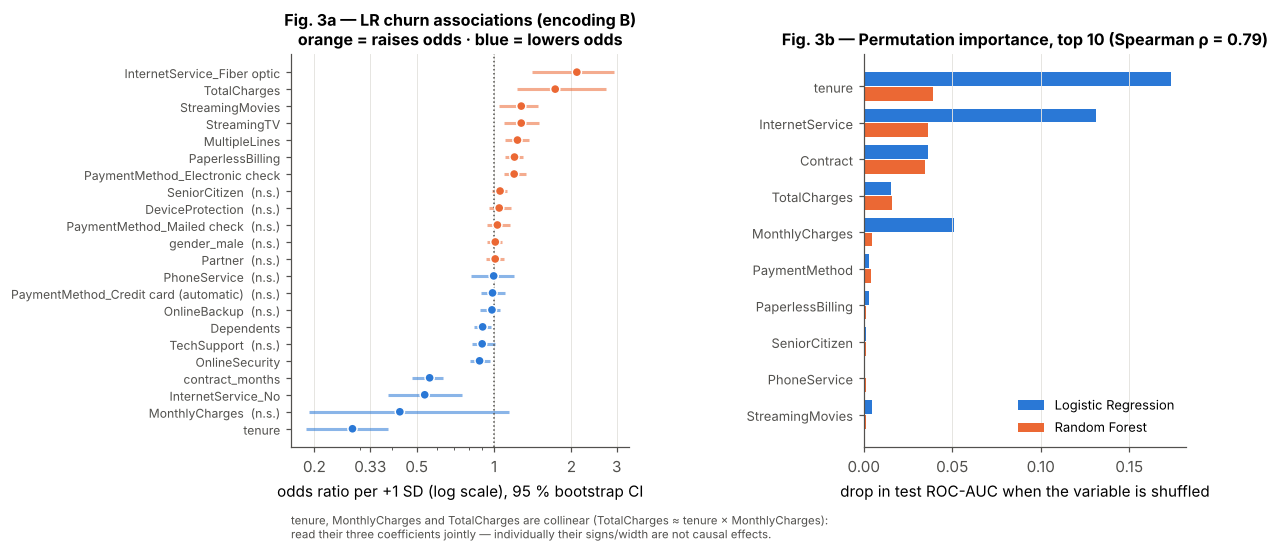

In [16]:
# ---- Figure 3: churn drivers — interpretable LR (encoding B) vs RF -------------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1.05, 1]})
o = OR.copy(); yy = np.arange(len(o))
col = np.where(o["odds_ratio_per_SD"] > 1, C["rf"], C["lr"])
a1.hlines(yy, o.ci_low, o.ci_high, color=col, lw=2, alpha=0.55)
a1.scatter(o["odds_ratio_per_SD"], yy, color=col, s=36, zorder=3, edgecolor="white", linewidth=1)
a1.axvline(1, color=C["ink2"], lw=1, ls=":"); a1.set_xscale("log")
a1.set_xticks([0.2, 0.33, 0.5, 1, 2, 3], ["0.2", "0.33", "0.5", "1", "2", "3"])
a1.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
a1.set_yticks(yy, [n + ("" if s else "  (n.s.)") for n, s in zip(o.index, o["CI excludes 1"])], fontsize=8)
a1.set_xlabel("odds ratio per +1 SD (log scale), 95 % bootstrap CI")
a1.set_title("Fig. 3a — LR churn associations (encoding B)\norange = raises odds · blue = lowers odds")
a1.grid(axis="y", visible=False)
a1.text(0.0, -0.17, "tenure, MonthlyCharges and TotalCharges are collinear (TotalCharges ≈ tenure × MonthlyCharges):\n"
        "read their three coefficients jointly — individually their signs/width are not causal effects.",
        transform=a1.transAxes, fontsize=7.5, color=C["ink2"], va="top")

top = PI.head(10)[::-1]; yy = np.arange(len(top)); h = 0.38
a2.barh(yy + h / 2 + 0.01, top["LogReg"], h, color=C["lr"], label="Logistic Regression")
a2.barh(yy - h / 2 - 0.01, top["RandomForest"], h, color=C["rf"], label="Random Forest")
a2.set_yticks(yy, top.index, fontsize=8.5); a2.grid(axis="y", visible=False)
a2.set_xlabel("drop in test ROC-AUC when the variable is shuffled")
a2.set_title(f"Fig. 3b — Permutation importance, top 10 (Spearman ρ = {rho:.2f})")
a2.legend(fontsize=8.5, loc="lower right")
fig.tight_layout(); savefig(fig, "fig3_exp2_churn_drivers"); plt.show()

## 6. Experiment 3 — PCA on encoded, scaled predictors (no labels)
*Owner: Kola Karan*
PCA is fitted on the training predictors only (encoding B: one column per business fact, so no artificial "no-internet" axis from duplicated dummies). `y` is not used until the cell marked **labels unsealed**.

In [17]:
prepU = make_prep("B_compact").fit(X_train)                 # unsupervised: X only
Z_train, Z_test = prepU.transform(X_train), prepU.transform(X_test)
FEAT = list(Z_train.columns)
pca = PCA(random_state=SEED).fit(Z_train)
evr = pca.explained_variance_ratio_; cum = np.cumsum(evr)
K90 = int(np.searchsorted(cum, PCA_VAR_TARGET) + 1)
LOAD = pd.DataFrame(pca.components_[:2].T, index=FEAT, columns=["PC1", "PC2"])
for pc in LOAD:                                              # sign convention: largest |loading| positive
    if LOAD[pc].iloc[LOAD[pc].abs().argmax()] < 0:
        LOAD[pc] *= -1
LOAD.to_csv(RES_DIR / "table5_pca_loadings_pc1_pc2.csv")
top3 = {pc: list(LOAD[pc].abs().sort_values(ascending=False).index[:3]) for pc in LOAD}
print(f"{len(FEAT)} encoded features | PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%}, PC1+PC2 {cum[1]:.1%} | "
      f"{K90} PCs reach {PCA_VAR_TARGET:.0%}")
print("top-|loading| variables:", top3)
log_experiment("E3", "PCA", {"encoding": "B_compact"}, "train(unsupervised)",
               {"evr_pc1": evr[0], "evr_pc2": evr[1], "k90": K90, "n_features": len(FEAT)})
LOAD.sort_values("PC1").round(3)

22 encoded features | PC1 25.1%, PC2 14.1%, PC1+PC2 39.2% | 15 PCs reach 90%
top-|loading| variables: {'PC1': ['MonthlyCharges', 'TotalCharges', 'StreamingMovies'], 'PC2': ['contract_months', 'PaymentMethod_Electronic check', 'tenure']}


,PC1,PC2
InternetService_No,-0.283,0.220
PaymentMethod_Mailed check,-0.199,0.111
gender_male,-0.012,0.003
Dependents,-0.006,0.259
PhoneService,0.030,-0.063
PaymentMethod_Electronic check,0.065,-0.364
PaymentMethod_Credit card (automatic),0.069,0.196
SeniorCitizen,0.088,-0.189
contract_months,0.101,0.441
Partner,0.117,0.233


In [18]:
# ---- Robustness of PC1/PC2: bootstrap rows & alternative encoding -----------------------
rng = np.random.default_rng(SEED)
ref = pca.components_[:2]
cos = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(Z_train), len(Z_train))
    comp = PCA(n_components=2, random_state=SEED).fit(Z_train.iloc[idx]).components_
    cos.append([abs(comp[i] @ ref[i]) for i in range(2)])      # |cosine|: PCA signs are arbitrary
cos = np.array(cos)
ZA = make_prep("A_onehot").fit(X_train).transform(X_train)
SA = PCA(n_components=2, random_state=SEED).fit_transform(ZA); SB = pca.transform(Z_train)[:, :2]
cross = np.abs(np.corrcoef(SA.T, SB.T)[:2, 2:])
ROB = pd.DataFrame({"bootstrap |cos| mean": cos.mean(0), "bootstrap |cos| 5th pct": np.percentile(cos, 5, 0),
                    "|r| with same PC under encoding A": np.diag(cross),
                    "|r| with other PC under encoding A": [cross[0, 1], cross[1, 0]]}, index=["PC1", "PC2"])
ROB.to_csv(RES_DIR / "table6_pca_robustness.csv")
for i, pc in enumerate(["PC1", "PC2"]):
    log_experiment("E3", "PCA-robustness", {"component": pc, "n_boot": N_BOOT}, "train(unsupervised)",
                   ROB.iloc[i].to_dict())
ROB.round(3)

,bootstrap |cos| mean,bootstrap |cos| 5th pct,|r| with same PC under encoding A,|r| with other PC under encoding A
PC1,1.000,0.999,0.725,0.466
PC2,0.999,0.998,0.678,0.652


saved → figures/fig4_exp3_pca_variance_loadings.png


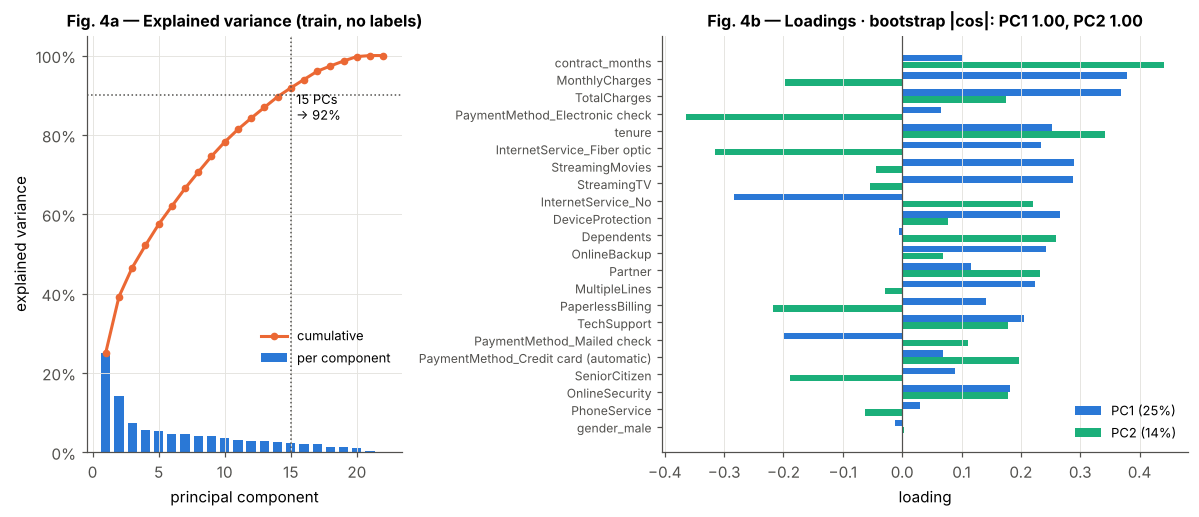

In [19]:
# ---- Figure 4: what the first two components are (variance + loadings) ------------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [0.75, 1.25]})
k = np.arange(1, len(evr) + 1)
a1.bar(k, evr, color=C["lr"], width=0.7, label="per component")
a1.plot(k, cum, "-o", color=C["rf"], ms=4, label="cumulative")
a1.axhline(PCA_VAR_TARGET, color=C["ink2"], ls=":", lw=1); a1.axvline(K90, color=C["ink2"], ls=":", lw=1)
a1.text(K90 + 0.4, cum[K90 - 1] - 0.08, f"{K90} PCs\n→ {cum[K90 - 1]:.0%}", fontsize=8.5)
a1.yaxis.set_major_formatter(PercentFormatter(1)); a1.set(xlabel="principal component", ylabel="explained variance")
a1.set_title("Fig. 4a — Explained variance (train, no labels)"); a1.legend(fontsize=8.5, loc="lower right", bbox_to_anchor=(1, 0.18))

L = LOAD.reindex(LOAD.abs().max(axis=1).sort_values().index)
yy = np.arange(len(L)); h = 0.38
a2.barh(yy + h / 2 + 0.01, L["PC1"], h, color=C["lr"], label=f"PC1 ({evr[0]:.0%})")
a2.barh(yy - h / 2 - 0.01, L["PC2"], h, color=C["aqua"], label=f"PC2 ({evr[1]:.0%})")
a2.axvline(0, color=C["ink2"], lw=0.8); a2.set_yticks(yy, L.index, fontsize=8); a2.grid(axis="y", visible=False)
a2.set_xlabel("loading"); a2.legend(fontsize=8.5, loc="lower right")
a2.set_title(f"Fig. 4b — Loadings · bootstrap |cos|: PC1 {cos[:, 0].mean():.2f}, PC2 {cos[:, 1].mean():.2f}")
fig.tight_layout(); savefig(fig, "fig4_exp3_pca_variance_loadings"); plt.show()

### Labels unsealed — how churn sits on the unsupervised axes
Only after PCA is fixed do we overlay churn: left, the customer density with no labels; right, the churn rate in each hexagon of the same plane.

saved → figures/fig5_exp3_pca_plane_churn.png


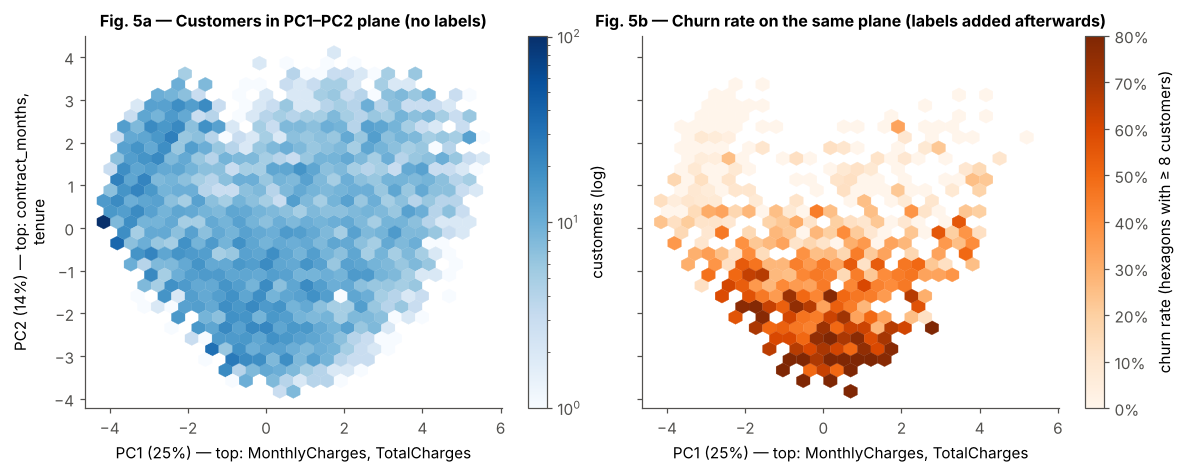

point-biserial correlation of each PC score with churn (train): {'PC1': 0.006, 'PC2': -0.507}


In [20]:
S = pca.transform(Z_train)[:, :2]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
hb1 = a1.hexbin(S[:, 0], S[:, 1], gridsize=28, cmap="Blues", mincnt=1, bins="log", linewidths=0.2)
fig.colorbar(hb1, ax=a1, label="customers (log)")
a1.set_title("Fig. 5a — Customers in PC1–PC2 plane (no labels)")
hb2 = a2.hexbin(S[:, 0], S[:, 1], C=y_train, reduce_C_function=np.mean, gridsize=28, cmap="Oranges",
                mincnt=8, vmin=0, vmax=0.8, linewidths=0.2)
fig.colorbar(hb2, ax=a2, label="churn rate (hexagons with ≥ 8 customers)", format=PercentFormatter(1))
a2.set_title("Fig. 5b — Churn rate on the same plane (labels added afterwards)")
for a in (a1, a2):
    a.set_xlabel(f"PC1 ({evr[0]:.0%}) — top: {', '.join(top3['PC1'][:2])}")
    a.grid(False)
a1.set_ylabel(f"PC2 ({evr[1]:.0%}) — top: {top3['PC2'][0]},\n{top3['PC2'][2]}")
fig.tight_layout(); savefig(fig, "fig5_exp3_pca_plane_churn"); plt.show()

corr_pc = pd.Series({pc: np.corrcoef(S[:, i], y_train)[0, 1] for i, pc in enumerate(["PC1", "PC2"])})
print("point-biserial correlation of each PC score with churn (train):", corr_pc.round(3).to_dict())

In [21]:
# ---- Original predictors vs reduced PCA representation (same folds, same encoding B) ------
E3, rows = {}, []
for rep, n_pcs in [("original (encoding B)", None), ("PCA, 2 PCs", 2), (f"PCA, {K90} PCs (90 % var.)", K90)]:
    for name in ["LogReg", "RandomForest"]:
        model = make_model(name, "B_compact", n_pcs)
        if n_pcs is None:
            folds, proba = E2[("B_compact", name)]["folds"], E2[("B_compact", name)]["proba"]
        else:
            folds, _ = cross_validate_model(model)
            _, proba = fit_and_test(model)
            log_experiment("E3", name, {"encoding": "B_compact", "n_pcs": n_pcs}, f"cv{CV_FOLDS}_mean",
                           folds.mean().to_dict())
            log_experiment("E3", name, {"encoding": "B_compact", "n_pcs": n_pcs}, "test", metrics_at(y_test, proba))
        t = metrics_at(y_test, proba)
        E3[(rep, name)] = {"folds": folds, "test": t}
        rows.append({"representation": rep, "model": name, "CV ROC-AUC": folds.roc_auc.mean(),
                     "CV ROC-AUC sd": folds.roc_auc.std(), "CV PR-AUC": folds.pr_auc.mean(),
                     "test ROC-AUC": t["roc_auc"], "test PR-AUC": t["pr_auc"], "test recall": t["recall"]})
TABLE7 = pd.DataFrame(rows).set_index(["representation", "model"])
TABLE7.to_csv(RES_DIR / "table7_exp3_original_vs_pca.csv")
assert pd.util.hash_pandas_object(X_test).sum() == TEST_FINGERPRINT
TABLE7.round(3)

CV ROC-AUC  CV ROC-AUC sd  CV PR-AUC  \
representation          model                                                
original (encoding B)   LogReg             0.846          0.014      0.662   
                        RandomForest       0.847          0.011      0.664   
PCA, 2 PCs              LogReg             0.831          0.011      0.628   
                        RandomForest       0.817          0.016      0.602   
PCA, 15 PCs (90 % var.) LogReg             0.844          0.013      0.658   
                        RandomForest       0.833          0.011      0.623   

                                      test ROC-AUC  test PR-AUC  test recall  
representation          model                                                 
original (encoding B)   LogReg               0.842        0.633        0.561  
                        RandomForest         0.846        0.658        0.500  
PCA, 2 PCs              LogReg               0.822        0.598        0.487  
                        RandomForest         0.810        0.580        0.473  
PCA, 15 PCs (90 % var.) LogReg               0.837        0.629        0.535  
                        RandomForest         0.825        0.606        0.465

saved → figures/fig6_exp3_original_vs_pca.png


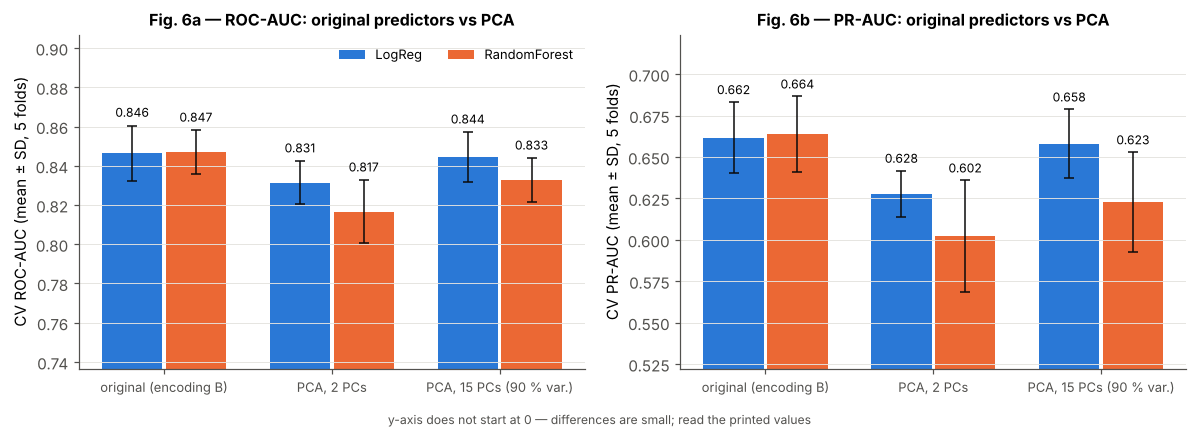

H2: PC1/PC2 top-3 variables disjoint → True; LR ROC-AUC loss 2 PCs = 0.015 (≥0.03?), 15 PCs = 0.002 (≤0.01?) → False  ⇒ supported: False


In [22]:
# ---- Figure 6: predictive cost of compression ---------------------------------------
reps = list(dict.fromkeys(TABLE7.index.get_level_values(0)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, metric, lab in ((axes[0], "roc_auc", "ROC-AUC"), (axes[1], "pr_auc", "PR-AUC")):
    x = np.arange(len(reps)); w = 0.36
    for j, (name, col) in enumerate((("LogReg", C["lr"]), ("RandomForest", C["rf"]))):
        mean = [E3[(r, name)]["folds"][metric].mean() for r in reps]
        sd = [E3[(r, name)]["folds"][metric].std() for r in reps]
        xs = x + (j - 0.5) * (w + 0.02)
        ax.bar(xs, mean, w, color=col, label=name)
        ax.errorbar(xs, mean, yerr=sd, fmt="none", ecolor=C["ink"], capsize=3, elinewidth=1)
        for xi, m, e in zip(xs, mean, sd):
            ax.text(xi, m + e + 0.003, f"{m:.3f}", ha="center", va="bottom", fontsize=8)
    lo = min(E3[k]["folds"][metric].mean() for k in E3)
    ax.set_ylim(max(0, lo - 0.08), min(1, max(E3[k]["folds"][metric].mean() for k in E3) + 0.06))
    ax.set_xticks(x, reps, fontsize=8.5); ax.grid(axis="x", visible=False)
    ax.set_ylabel(f"CV {lab} (mean ± SD, {CV_FOLDS} folds)")
    ax.set_title(f"Fig. 6{'ab'[ax is axes[1]]} — {lab}: original predictors vs PCA")
axes[0].legend(fontsize=8.5, loc="upper right", ncol=2)
fig.text(0.5, -0.03, "y-axis does not start at 0 — differences are small; read the printed values",
         ha="center", fontsize=8, color=C["ink2"])
fig.tight_layout(); savefig(fig, "fig6_exp3_original_vs_pca"); plt.show()

orig = E3[("original (encoding B)", "LogReg")]["folds"].roc_auc.mean()
d2 = orig - E3[("PCA, 2 PCs", "LogReg")]["folds"].roc_auc.mean()
d90 = orig - E3[(f"PCA, {K90} PCs (90 % var.)", "LogReg")]["folds"].roc_auc.mean()
H2_axes = len(set(top3["PC1"]) & set(top3["PC2"])) == 0
H2_loss = (d2 >= 0.03) and (d90 <= 0.01)
H2_SUPPORTED = bool(H2_axes and H2_loss)
print(f"H2: PC1/PC2 top-3 variables disjoint → {H2_axes}; LR ROC-AUC loss 2 PCs = {d2:.3f} (≥0.03?), "
      f"{K90} PCs = {d90:.3f} (≤0.01?) → {H2_loss}  ⇒ supported: {H2_SUPPORTED}")

## 7. Experiment log and verdicts

In [23]:
LOG = pd.DataFrame(EXPERIMENT_LOG)
LOG.to_csv(RES_DIR / "experiment_log.csv", index=False)
assert pd.util.hash_pandas_object(X_test).sum() == TEST_FINGERPRINT
SUMMARY = {
    "seed": SEED, "n": int(len(df)), "n_train": int(len(y_train)), "n_test": int(len(y_test)),
    "churn_rate": round(float(df[TARGET].mean()), 4),
    "E1_test": {n: {k: round(float(v), 4) for k, v in metrics_at(y_test, E1[n]["proba"]).items()
                    if k in ("roc_auc", "pr_auc", "recall", "precision", "mcc", "accuracy")} for n in E1},
    "E1_cv_roc_auc": {n: round(float(E1[n]["folds"].roc_auc.mean()), 4) for n in E1},
    "H1_supported": H1_SUPPORTED, "H2_supported": H2_SUPPORTED, "H2_axes_distinct": H2_axes,
    "H2_loss_2pcs": round(float(d2), 4), "H2_loss_k90": round(float(d90), 4), "k90": K90,
    "evr_pc1_pc2": [round(float(evr[0]), 4), round(float(evr[1]), 4)], "top3_loadings": top3,
    "driver_rank_spearman": round(float(rho), 3),
}
(RES_DIR / "summary.json").write_text(json.dumps(SUMMARY, indent=2))
print(json.dumps(SUMMARY, indent=2))
print(f"\n{len(LOG)} log rows → results/experiment_log.csv")
LOG[["exp_id", "model", "config", "split", "roc_auc", "pr_auc", "recall", "precision"]].fillna("")

{
  "seed": 42,
  "n": 7043,
  "n_train": 5634,
  "n_test": 1409,
  "churn_rate": 0.2654,
  "E1_test": {
    "LogReg": {
      "roc_auc": 0.8417,
      "pr_auc": 0.6312,
      "recall": 0.5668,
      "precision": 0.6604,
      "mcc": 0.4859,
      "accuracy": 0.8077
    },
    "RandomForest": {
      "roc_auc": 0.844,
      "pr_auc": 0.6549,
      "recall": 0.508,
      "precision": 0.6786,
      "mcc": 0.4659,
      "accuracy": 0.8055
    }
  },
  "E1_cv_roc_auc": {
    "LogReg": 0.8462,
    "RandomForest": 0.8477
  },
  "H1_supported": true,
  "H2_supported": false,
  "H2_axes_distinct": true,
  "H2_loss_2pcs": 0.015,
  "H2_loss_k90": 0.002,
  "k90": 15,
  "evr_pc1_pc2": [
    0.251,
    0.1411
  ],
  "top3_loadings": {
    "PC1": [
      "MonthlyCharges",
      "TotalCharges",
      "StreamingMovies"
    ],
    "PC2": [
      "contract_months",
      "PaymentMethod_Electronic check",
      "tenure"
    ]
  },
  "driver_rank_spearman": 0.791
}

25 log rows → results/experiment_log.cs

,exp_id,model,config,split,roc_auc,pr_auc,recall,precision
0,BASE,NeverChurns,{},test,0.5,0.2654,0.0,0.0
1,E1,LogReg,"{""encoding"": ""A_onehot"", ""threshold"": 0.5}",cv5_mean,0.8462,0.6613,0.5452,0.6525
2,E1,LogReg,"{""encoding"": ""A_onehot"", ""threshold"": 0.5}",test,0.8417,0.6312,0.5668,0.6604
3,E1,RandomForest,"{""encoding"": ""A_onehot"", ""threshold"": 0.5}",cv5_mean,0.8477,0.6624,0.491,0.6864
4,E1,RandomForest,"{""encoding"": ""A_onehot"", ""threshold"": 0.5}",test,0.844,0.6549,0.508,0.6786
5,E1-thr,LogReg,"{""encoding"": ""A_onehot"", ""threshold"": 0.1}",test,0.8417,0.6312,0.9465,0.4064
6,E1-thr,LogReg,"{""encoding"": ""A_onehot"", ""threshold"": 0.2}",test,0.8417,0.6312,0.8556,0.4665
7,E1-thr,LogReg,"{""encoding"": ""A_onehot"", ""threshold"": 0.35}",test,0.8417,0.6312,0.7086,0.5441
8,E1-thr,LogReg,"{""encoding"": ""A_onehot"", ""threshold"": 0.5}",test,0.8417,0.6312,0.5668,0.6604
9,E1-thr,LogReg,"{""encoding"": ""A_onehot"", ""threshold"": 0.65}",test,0.8417,0.6312,0.3075,0.7468


### Scientific interpretation (short answers — full discussion in the report)

**Why is churn recall not sufficient by itself?** Recall can be pushed towards 1 simply by flagging more customers: in Table 1b the same Logistic Regression reaches recall 0.95 at threshold 0.10, but it then flags 62 % of all customers and only 41 % of the flags are real churners (517 false alarms on 1,409 test customers). Recall counts only the churners we catch, never the cost of the people we wrongly target. Every flag costs a retention action, so precision (how many flagged customers really leave), PR-AUC (quality of the whole ranking for churners) and the number of customers flagged must be reported alongside recall; the right threshold is a business decision (cost of an offer vs value of a saved customer).

**What is lost with PCA instead of business variables?** Each PC is a weighted mix of many standardised variables, so a coefficient on "PC2" cannot be turned into an action ("offer a 1-year contract"). Components are fitted to explain *variance in X*, not churn, so low-variance but predictive signals can be discarded; and the axes depend on encoding and scaling choices. We keep orthogonality and compression, but lose units, sign stability and actionability.

**How do we avoid treating correlation as causation?** Odds ratios and permutation importances describe *associations in observational data*. Month-to-month contracts, fibre and electronic checks co-occur with short tenure, so they confound one another; customers also self-select into contracts. Claims about causes require an intervention design (A/B-tested retention offer, randomised contract incentives) or at least causal adjustment with explicit assumptions (DAG, matching), and validation on later data. In the report we phrase findings as "associated with", never "causes".

## 8. Oral-defense parameter changes

**Group:** Pinninti Sai Anish · Paravasthu Vamsi Krishna Suri · Kola Karan

Each member makes **one** change in the configuration cell (§0), re-runs all cells, and explains the effect. Seeds stay fixed, so any difference is caused by the change.

| Member | Owns | Change | What should move |
|---|---|---|---|
| Pinninti Sai Anish | inspection, leakage audit, protocol | `THRESHOLD = 0.35` | recall 0.57 → 0.71, precision 0.66 → 0.54 (Table 1b, Fig. 2 dots) — AUCs unchanged |
| Paravasthu Vamsi Krishna Suri | Experiments 1 & 2 | `LR_C = 0.05` | LR coefficients shrink; driver ranking and AUC barely change |
| Kola Karan | Experiment 3 (PCA) | `PCA_VAR_TARGET = 0.80` | fewer PCs → larger AUC loss (Table 7, Fig. 6) |
| any | robustness | `SEED = 7` | do the conclusions survive a different split? |

## 9. MLflow experiment tracking
*Owner: Pinninti Sai Anish*

Every configuration from Experiments 1–3 (LR and RF × encoding A, encoding B, B + 2 PCs, B + 90 %-variance PCs) becomes one **MLflow run**, nested under a parent run `model-selection`. Nothing is retrained to fill MLflow: each run is logged from the fold metrics and test probabilities already computed in §4–§6, so the tracked numbers *are* the report numbers — and a check below asserts it.

Logged per run: parameters (model, encoding, PCs, hyper-parameters, seed, threshold), CV mean ± SD for ROC-AUC, PR-AUC, recall, precision, F1, MCC and accuracy, the five fold ROC-AUCs as steps, the fold table, and the test metrics (reporting only — §10 never uses them to choose). The parent run records the dataset, its SHA-256 and the test-set fingerprint.

In [24]:
# ---- 9a. MLflow setup -------------------------------------------------------------------------
import sys, hashlib, logging, subprocess, socket, importlib
os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")   # no usage data sent to MLflow's servers
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import mlflow, mlflow.sklearn
from mlflow import MlflowClient
from mlflow.models import infer_signature
logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="mlflow")

IN_COLAB = "google.colab" in sys.modules
TRACKING_URI = f"sqlite:///{ROOT / 'mlflow.db'}"
EXPERIMENT, MODEL_NAME, MODEL_ALIAS = "telco-churn", "telco-churn-classifier", "champion"
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT)
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"mlflow {mlflow.__version__} | tracking store: mlflow.db (SQLite, next to this notebook) | Colab: {IN_COLAB}")
print(f"data sha256: {DATA_SHA256[:16]}…")

mlflow 3.17.2 | tracking store: mlflow.db (SQLite, next to this notebook) | Colab: False
data sha256: 16320c9c1ec72448…


The registered model must be loadable **outside** this notebook (by the API in §11), so encoding B's row-wise rule is written to a small module, `churn_features.py`. The next cell proves it is byte-for-byte the same transformation as §3b before anything uses it.

In [25]:
%%writefile churn_features.py
"""Encoding B (notebook §3b) as an importable module, so the registered model loads outside the notebook."""
import pandas as pd

NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
BINARY_YN = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
SERVICES = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]
NOMINAL = ["InternetService", "PaymentMethod"]
CAT = ["gender", "SeniorCitizen"] + BINARY_YN + SERVICES + NOMINAL + ["Contract"]
PREDICTORS = NUM + CAT
CONTRACT_MONTHS = {"Month-to-month": 0, "One year": 12, "Two year": 24}


def compact_encode(frame):
    # Encoding B: fixed domain rules, applied row by row — no fitting, no labels.
    out = pd.DataFrame(index=frame.index)
    out[NUM] = frame[NUM].astype(float)
    out["gender_male"] = (frame["gender"] == "Male").astype(int)
    out["SeniorCitizen"] = frame["SeniorCitizen"].astype(int)
    for c in BINARY_YN + SERVICES:
        out[c] = (frame[c] == "Yes").astype(int)
    out["contract_months"] = frame["Contract"].map(CONTRACT_MONTHS)
    if out["contract_months"].isna().any():
        raise ValueError("unknown Contract value")
    out[NOMINAL] = frame[NOMINAL]
    return out

Writing churn_features.py


In [26]:
# ---- 9b. Prove the module equals §3b, then use it for every pipeline built from here on --------
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import churn_features
importlib.reload(churn_features)
assert churn_features.PREDICTORS == PREDICTORS and churn_features.CONTRACT_MONTHS == CONTRACT_MONTHS
pd.testing.assert_frame_equal(churn_features.compact_encode(X_train), compact_encode(X_train))
pd.testing.assert_frame_equal(churn_features.compact_encode(X_test), compact_encode(X_test))
compact_encode = churn_features.compact_encode      # make_prep() looks this name up at call time
print(f"churn_features.compact_encode == §3b on all {len(X_train):,} train and {len(X_test):,} test rows ✓")

churn_features.compact_encode == §3b on all 5,634 train and 1,409 test rows ✓


In [27]:
# ---- 9c. Gather the 8 configurations from the results already computed in §4–§6 --------------
WIDTH = {e: make_prep(e).fit(X_train).transform(X_train.head(1)).shape[1] for e in ("A_onehot", "B_compact")}
REP = {2: "PCA, 2 PCs", K90: f"PCA, {K90} PCs (90 % var.)"}
CONFIGS = []
for enc in ("A_onehot", "B_compact"):
    for name in ("LogReg", "RandomForest"):
        r = E2[(enc, name)]
        CONFIGS.append({"model": name, "encoding": enc, "n_pcs": None, "folds": r["folds"],
                        "test": metrics_at(y_test, r["proba"]), "proba": r["proba"]})
for n_pcs in (2, K90):
    for name in ("LogReg", "RandomForest"):
        r = E3[(REP[n_pcs], name)]
        CONFIGS.append({"model": name, "encoding": "B_compact", "n_pcs": n_pcs, "folds": r["folds"],
                        "test": r["test"], "proba": None})
for c in CONFIGS:
    c["name"] = f"{c['model']}-{c['encoding']}" + ("" if c["n_pcs"] is None else f"-pca{c['n_pcs']}")
    c["n_features"] = WIDTH[c["encoding"]]
print(len(CONFIGS), "configurations:", [c["name"] for c in CONFIGS])

8 configurations: ['LogReg-A_onehot', 'RandomForest-A_onehot', 'LogReg-B_compact', 'RandomForest-B_compact', 'LogReg-B_compact-pca2', 'RandomForest-B_compact-pca2', 'LogReg-B_compact-pca15', 'RandomForest-B_compact-pca15']


In [28]:
# ---- 9d. One MLflow run per configuration ------------------------------------------------------
METRIC_KEYS = ["roc_auc", "pr_auc", "recall", "precision", "f1", "mcc", "accuracy"]
train_ds = mlflow.data.from_pandas(X_train.assign(Churn=y_train), source=SOURCE_URL, name="telco-train",
                                   targets="Churn")

with mlflow.start_run(run_name="model-selection") as parent:
    mlflow.log_input(train_ds, context="training")
    mlflow.log_params({"seed": SEED, "test_size": TEST_SIZE, "cv_folds": CV_FOLDS, "threshold": THRESHOLD,
                       "n_train": len(y_train), "n_test": len(y_test), "k90": K90})
    mlflow.set_tags({"data_sha256": DATA_SHA256, "test_fingerprint": str(TEST_FINGERPRINT),
                     "notebook": "telco_churn_pca.ipynb"})
    for c in CONFIGS:
        with mlflow.start_run(run_name=c["name"], nested=True) as run:
            p = {"model": c["model"], "encoding": c["encoding"], "n_pcs": c["n_pcs"] or "none",
                 "n_features": c["n_features"], "seed": SEED, "threshold": THRESHOLD}
            p |= ({"C": LR_C, "penalty": "l2"} if c["model"] == "LogReg" else
                  {"n_estimators": RF_TREES, "min_samples_leaf": RF_MIN_LEAF, "max_features": "sqrt"})
            mlflow.log_params(p)
            for i, v in enumerate(c["folds"].roc_auc):
                mlflow.log_metric("cv_fold_roc_auc", float(v), step=i)
            res = {f"cv_{m}_mean": float(c["folds"][m].mean()) for m in METRIC_KEYS}
            res |= {f"cv_{m}_sd": float(c["folds"][m].std()) for m in METRIC_KEYS}
            res |= {f"test_{m}": float(c["test"][m]) for m in METRIC_KEYS}
            mlflow.log_metrics(res)
            mlflow.log_text(c["folds"].to_csv(index=False), "cv_folds.csv")
            c["result"], c["run_id"] = res, run.info.run_id
PARENT_ID = parent.info.run_id

# The tracked numbers must be exactly the ones in the report tables
by = {c["name"]: c["result"] for c in CONFIGS}
assert np.isclose(by["LogReg-A_onehot"]["test_roc_auc"], TABLE1.loc["LogReg", "test ROC-AUC"])
assert np.isclose(by["RandomForest-A_onehot"]["test_roc_auc"], TABLE1.loc["RandomForest", "test ROC-AUC"])
for (rep, name), row in TABLE7.iterrows():
    key = {"original (encoding B)": f"{name}-B_compact", REP[2]: f"{name}-B_compact-pca2",
           REP[K90]: f"{name}-B_compact-pca{K90}"}[rep]
    assert np.isclose(by[key]["cv_roc_auc_mean"], row["CV ROC-AUC"]), key
assert pd.util.hash_pandas_object(X_test).sum() == TEST_FINGERPRINT
print("MLflow runs match Tables 1, 2 and 7 exactly ✓  | test-set fingerprint unchanged ✓\n")

runs = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string=f"tags.mlflow.parentRunId = '{PARENT_ID}'")
runs[["tags.mlflow.runName", "params.model", "params.encoding", "params.n_pcs", "metrics.cv_roc_auc_mean",
      "metrics.cv_roc_auc_sd", "metrics.cv_pr_auc_mean", "metrics.test_roc_auc", "metrics.test_recall"]] \
    .rename(columns=lambda s: s.split(".")[-1]).sort_values("cv_roc_auc_mean", ascending=False).round(4)

MLflow runs match Tables 1, 2 and 7 exactly ✓  | test-set fingerprint unchanged ✓



,runName,model,encoding,n_pcs,cv_roc_auc_mean,cv_roc_auc_sd,cv_pr_auc_mean,test_roc_auc,test_recall
6,RandomForest-A_onehot,RandomForest,A_onehot,none,0.8477,0.0099,0.6624,0.8440,0.5080
4,RandomForest-B_compact,RandomForest,B_compact,none,0.8468,0.0112,0.6638,0.8460,0.5000
5,LogReg-B_compact,LogReg,B_compact,none,0.8463,0.0142,0.6616,0.8421,0.5615
7,LogReg-A_onehot,LogReg,A_onehot,none,0.8462,0.0141,0.6613,0.8417,0.5668
1,LogReg-B_compact-pca15,LogReg,B_compact,15,0.8443,0.0127,0.6581,0.8373,0.5348
0,RandomForest-B_compact-pca15,RandomForest,B_compact,15,0.8327,0.0110,0.6229,0.8252,0.4652
3,LogReg-B_compact-pca2,LogReg,B_compact,2,0.8313,0.0110,0.6277,0.8216,0.4866
2,RandomForest-B_compact-pca2,RandomForest,B_compact,2,0.8166,0.0160,0.6022,0.8101,0.4733


**Reading the table.** It is read back from the MLflow store, not from Python variables, so it shows what anyone opening the MLflow UI will see. The ordering repeats the report: the two non-PCA Random Forests and the two non-PCA Logistic Regressions sit within 0.002 of each other on CV ROC-AUC, and compression to 2 PCs costs the most.

## 10. Model selection, registry and MLflow UI
*Owner: Pinninti Sai Anish*

**Selection rule (uses CV only — the test set never enters the choice):**
1. find the configuration with the highest mean CV ROC-AUC;
2. every configuration within **one standard error** of it (SD / √5) counts as statistically tied — the same logic as H1 ("within noise, interpretable is enough");
3. among the tied ones take the **simplest**: no PCA before PCA, Logistic Regression before Random Forest, then fewer features.

The champion is refitted on the full training set, logged with its figures and odds ratios, saved with **skops** (a format that, unlike pickle, cannot execute code when loaded) and registered as `telco-churn-classifier@champion`.

In [29]:
# ---- 10a. Apply the rule ------------------------------------------------------------------------
best = max(CONFIGS, key=lambda c: c["result"]["cv_roc_auc_mean"])
se = best["result"]["cv_roc_auc_sd"] / np.sqrt(CV_FOLDS)
cutoff = best["result"]["cv_roc_auc_mean"] - se
tied = [c for c in CONFIGS if c["result"]["cv_roc_auc_mean"] >= cutoff]
CHAMP = min(tied, key=lambda c: (c["n_pcs"] is not None, c["model"] == "RandomForest", c["n_features"]))

BOARD = pd.DataFrame([{"config": c["name"], "CV ROC-AUC": c["result"]["cv_roc_auc_mean"],
                       "CV SD": c["result"]["cv_roc_auc_sd"], "tied with best (1 SE)": c in tied,
                       "test ROC-AUC (report only)": c["result"]["test_roc_auc"],
                       "test recall": c["result"]["test_recall"], "champion": c is CHAMP} for c in CONFIGS]) \
    .sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
with mlflow.start_run(run_id=PARENT_ID):
    mlflow.log_table(BOARD, "leaderboard.json")
    mlflow.set_tags({"selection_rule": "max CV ROC-AUC; within 1 SE = tied; no PCA > PCA, LR > RF, fewer features",
                     "champion": CHAMP["name"], "champion_run_id": CHAMP["run_id"]})
print(f"best CV ROC-AUC: {best['name']} {best['result']['cv_roc_auc_mean']:.4f} ± {best['result']['cv_roc_auc_sd']:.4f}"
      f"  → 1 SE = {se:.4f}, tie cut-off = {cutoff:.4f}")
print(f"tied: {[c['name'] for c in tied]}")
print(f"champion: {CHAMP['name']}")
BOARD.round(4)

best CV ROC-AUC: RandomForest-A_onehot 0.8477 ± 0.0099  → 1 SE = 0.0044, tie cut-off = 0.8433
tied: ['LogReg-A_onehot', 'RandomForest-A_onehot', 'LogReg-B_compact', 'RandomForest-B_compact', 'LogReg-B_compact-pca15']
champion: LogReg-B_compact


,config,CV ROC-AUC,CV SD,tied with best (1 SE),test ROC-AUC (report only),test recall,champion
0,RandomForest-A_onehot,0.8477,0.0099,True,0.8440,0.5080,False
1,RandomForest-B_compact,0.8468,0.0112,True,0.8460,0.5000,False
2,LogReg-B_compact,0.8463,0.0142,True,0.8421,0.5615,True
3,LogReg-A_onehot,0.8462,0.0141,True,0.8417,0.5668,False
4,LogReg-B_compact-pca15,0.8443,0.0127,True,0.8373,0.5348,False
5,RandomForest-B_compact-pca15,0.8327,0.0110,False,0.8252,0.4652,False
6,LogReg-B_compact-pca2,0.8313,0.0110,False,0.8216,0.4866,False
7,RandomForest-B_compact-pca2,0.8166,0.0160,False,0.8101,0.4733,False


saved → figures/fig7_champion_test.png


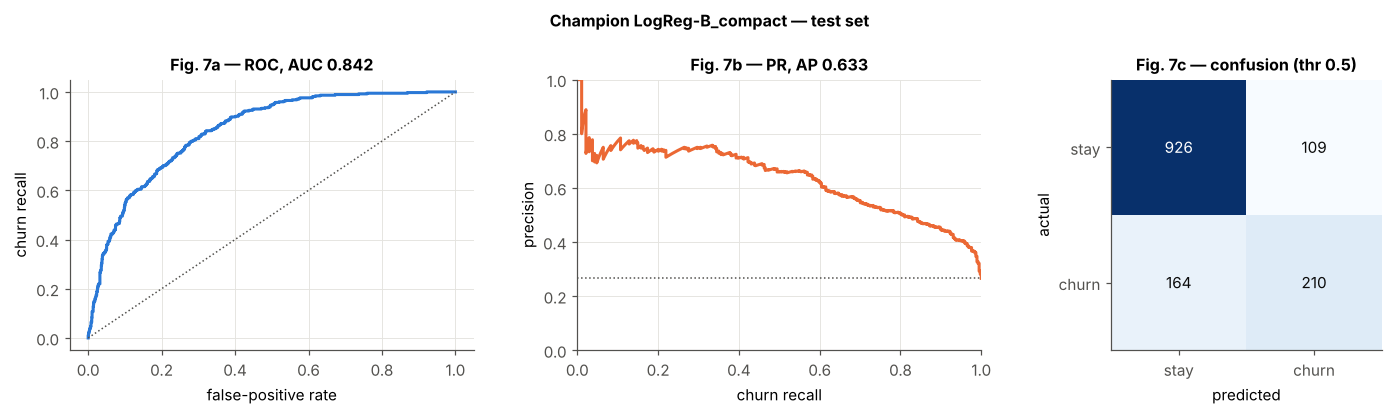

registered telco-churn-classifier version 1 → alias 'champion'  (skops trusted types: ['churn_features.compact_encode', 'numpy.dtype'])


,threshold,recall,precision,flagged_pct,fp,fn
0,0.10,0.947,0.406,0.618,517,20
1,0.20,0.858,0.468,0.487,365,53
2,0.35,0.709,0.543,0.346,223,109
3,0.50,0.561,0.658,0.226,109,164
4,0.65,0.305,0.745,0.109,39,260


In [30]:
# ---- 10b. Refit the champion, log artifacts, register it ---------------------------------------
champ_model = make_model(CHAMP["model"], CHAMP["encoding"], CHAMP["n_pcs"]).fit(X_train, y_train)
champ_proba = champ_model.predict_proba(X_test)[:, 1]
if CHAMP["proba"] is not None:   # refit with the module's encoder must give the notebook's predictions
    assert np.allclose(champ_proba, CHAMP["proba"]), "refit differs from the notebook model"
m = metrics_at(y_test, champ_proba)

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 0.8]})
fpr, tpr, _ = roc_curve(y_test, champ_proba)
a1.plot(fpr, tpr, color=C["lr"]); a1.plot([0, 1], [0, 1], ":", color=C["ink2"], lw=1)
a1.set(xlabel="false-positive rate", ylabel="churn recall", title=f"Fig. 7a — ROC, AUC {m['roc_auc']:.3f}")
pr, rc, _ = precision_recall_curve(y_test, champ_proba)
a2.plot(rc, pr, color=C["rf"]); a2.axhline(y_test.mean(), ls=":", color=C["ink2"], lw=1)
a2.set(xlabel="churn recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1), title=f"Fig. 7b — PR, AP {m['pr_auc']:.3f}")
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
a3.imshow(cm, cmap="Blues"); a3.grid(False)
for (i, j), v in np.ndenumerate(cm):
    a3.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else C["ink"])
a3.set_xticks([0, 1], ["stay", "churn"]); a3.set_yticks([0, 1], ["stay", "churn"])
a3.set(xlabel="predicted", ylabel="actual", title=f"Fig. 7c — confusion (thr {THRESHOLD})")
fig.suptitle(f"Champion {CHAMP['name']} — test set", fontsize=10.5, fontweight="bold")
fig.tight_layout(); savefig(fig, "fig7_champion_test"); plt.show()

thr_table = pd.DataFrame([{"threshold": t, **{k: metrics_at(y_test, champ_proba, t)[k]
                           for k in ("recall", "precision", "flagged_pct", "fp", "fn")}}
                          for t in (0.10, 0.20, 0.35, 0.50, 0.65)])
explainable = CHAMP["model"] == "LogReg" and CHAMP["n_pcs"] is None

# skops refuses to save any type it does not know; list them and allow only our encoder + numpy dtypes
import skops.io as sio
untrusted = sio.get_untrusted_types(data=sio.dumps(champ_model))
# allowed: our own encoder, numpy dtypes, and scikit-learn's own internal classes (they differ by sklearn
# version, e.g. Colab's sklearn adds compose._column_transformer._RemainderColsList); anything else is refused
SAFE_PREFIXES = ("numpy.dtype", "sklearn.")
assert all(t == "churn_features.compact_encode" or t.startswith(SAFE_PREFIXES) for t in untrusted), untrusted

with mlflow.start_run(run_id=CHAMP["run_id"]):
    mlflow.set_tag("champion", "true")
    mlflow.log_input(train_ds, context="training")
    mlflow.log_figure(fig, "figures/champion_test.png")
    mlflow.log_table(thr_table, "tables/threshold_tradeoff_test.json")
    if explainable:
        mlflow.log_table(OR.reset_index(names="feature"), "tables/odds_ratios_bootstrap.json")
    example = X_train.head(3)
    info = mlflow.sklearn.log_model(
        sk_model=champ_model, name="model", input_example=example,
        signature=infer_signature(example, champ_model.predict_proba(example)),
        registered_model_name=MODEL_NAME, code_paths=["churn_features.py"], pyfunc_predict_fn="predict_proba",
        serialization_format="skops", skops_trusted_types=untrusted,
        pip_requirements=["mlflow", "scikit-learn", "skops", "pandas", "numpy"],
        metadata={"config": CHAMP["name"], "threshold": THRESHOLD, "data_sha256": DATA_SHA256,
                  "cv_roc_auc": round(CHAMP["result"]["cv_roc_auc_mean"], 4),
                  "cv_roc_auc_sd": round(CHAMP["result"]["cv_roc_auc_sd"], 4),
                  "test": {k: round(v, 4) for k, v in CHAMP["result"].items() if k.startswith("test_")}})
client = MlflowClient()
VERSION = info.registered_model_version
client.set_registered_model_alias(MODEL_NAME, MODEL_ALIAS, VERSION)
client.update_model_version(MODEL_NAME, VERSION, description=(
    f"{CHAMP['name']} | CV ROC-AUC {CHAMP['result']['cv_roc_auc_mean']:.3f} ± {CHAMP['result']['cv_roc_auc_sd']:.3f}"
    f" | test ROC-AUC {m['roc_auc']:.3f} | chosen by the 1-SE rule on CV"))
print(f"registered {MODEL_NAME} version {VERSION} → alias '{MODEL_ALIAS}'  (skops trusted types: {untrusted})")
thr_table.round(3)

In [31]:
# ---- 10c. Reload from the registry exactly as a deployment would --------------------------------
loaded = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@{MODEL_ALIAS}")
reloaded = loaded.predict_proba(X_test)[:, 1]
assert np.allclose(reloaded, champ_proba)
pyf = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@{MODEL_ALIAS}")
print(f"registry reload: test ROC-AUC {roc_auc_score(y_test, reloaded):.4f} — identical predictions to the "
      f"refitted champion ✓ (pyfunc flavour also loads: {type(pyf).__name__})")

registry reload: test ROC-AUC 0.8421 — identical predictions to the refitted champion ✓ (pyfunc flavour also loads: PyFuncModel)


In [32]:

# ---- 10d. MLflow UI ------------------------------------------------------------------------------
# In Colab two ways to open it: (1) inside the notebook, through Colab's own proxy; (2) a temporary public
# https link (Cloudflare quick tunnel) that works in any browser. Set PUBLIC_LINKS = False to skip (2).
PUBLIC_LINKS = IN_COLAB
SERVERS = {}
from urllib.parse import urlparse

def port_open(port):
    with socket.socket() as s:
        return s.connect_ex(("127.0.0.1", port)) == 0

def wait_for(port, seconds=90):
    for _ in range(seconds * 2):
        if port_open(port):
            return True
        time.sleep(0.5)
    return False

def start_tunnel(port, name):
    """Public https link to a local port (no account). Anyone with the link can open it while it runs."""
    if not PUBLIC_LINKS:
        return None
    if not (ROOT / "cloudflared").exists():
        subprocess.run(["wget", "-q", "-O", str(ROOT / "cloudflared"), "https://github.com/cloudflare/cloudflared/"
                        "releases/latest/download/cloudflared-linux-amd64"], check=True)
        os.chmod(ROOT / "cloudflared", 0o755)
    log = RES_DIR / f"tunnel_{name}.log"
    SERVERS[f"tunnel_{name}"] = subprocess.Popen(
        [str(ROOT / "cloudflared"), "tunnel", "--no-autoupdate", "--url", f"http://127.0.0.1:{port}"],
        stdout=open(log, "w"), stderr=subprocess.STDOUT)
    for _ in range(60):
        hit = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", log.read_text())
        if hit:
            return hit.group(0)
        time.sleep(1)
    return None

import re
MLFLOW_PORT = 5000
mlflow_tunnel = start_tunnel(MLFLOW_PORT, "mlflow")
# MLflow 3 checks the Host header on every request and the Origin header on POSTs (the runs list is a POST):
# allow localhost, Colab's proxy domains, and the exact tunnel address — nothing else.
hosts = [f"localhost:{MLFLOW_PORT}", f"127.0.0.1:{MLFLOW_PORT}", "*.colab.dev", "*.colab.dev:*",
         "*.googleusercontent.com", "*.googleusercontent.com:*",
         "*.codatalab-user-runtimes.internal", "*.codatalab-user-runtimes.internal:*"]
origins = ["https://*.colab.dev", "https://*.googleusercontent.com", "https://*.codatalab-user-runtimes.internal*"]
if mlflow_tunnel:
    hosts.append(urlparse(mlflow_tunnel).netloc); origins.append(mlflow_tunnel)
subprocess.run(["pkill", "-f", "mlflow ui"], check=False)
SERVERS["mlflow"] = subprocess.Popen(
    [sys.executable, "-m", "mlflow", "ui", "--backend-store-uri", TRACKING_URI, "--host", "127.0.0.1",
     "--port", str(MLFLOW_PORT), "--x-frame-options", "NONE"],
    cwd=ROOT, stdout=open(RES_DIR / "mlflow_ui.log", "w"), stderr=subprocess.STDOUT,
    env={**os.environ, "MLFLOW_SERVER_ALLOWED_HOSTS": ",".join(hosts),
         "MLFLOW_SERVER_CORS_ALLOWED_ORIGINS": ",".join(origins)})
ok = wait_for(MLFLOW_PORT)
time.sleep(8)                                   # let the 4 workers finish starting before the first page load
print("MLflow UI running ✓" if ok else "MLflow UI did not start — see results/mlflow_ui.log")
print("public link:", mlflow_tunnel or (f"http://127.0.0.1:{MLFLOW_PORT}/" if not IN_COLAB else "off"))
print("in the UI: switch to 'Model training' (top left) → Experiments → telco-churn → Runs; 'Models' for the registry")
if IN_COLAB and ok:
    from google.colab import output
    output.serve_kernel_port_as_iframe(MLFLOW_PORT, height=700)


MLflow UI running ✓
public link: http://127.0.0.1:5000/
in the UI: switch to 'Model training' (top left) → Experiments → telco-churn → Runs; 'Models' for the registry


**Interpretation.** The Random Forest on encoding A has the highest CV ROC-AUC, but its lead over Logistic Regression on encoding B is about 0.001, far inside one standard error (~0.004). Under a rule fixed in advance, that is a tie, and the tie goes to the simpler, interpretable model — the same conclusion as H1, now reached by an explicit, reproducible procedure rather than by judgement. The registered model is the full pipeline (encoding → imputer → scaler → classifier), so it accepts raw customer rows, and reloading it from the registry reproduces the notebook's test predictions exactly.

**Limitation.** The rule's tie-breaker encodes a value judgement (prefer interpretable models). A team that cared only about ranking would pick the Random Forest; with differences this small, either choice is defensible, which is why the rule is written down before use.

## 11. Prediction API for the champion
*Owner: Pinninti Sai Anish*

A **FastAPI** service (`churn_api.py`) loads `telco-churn-classifier@champion` from the MLflow registry and exposes:

| Endpoint | Purpose |
|---|---|
| `POST /predict` | one customer → churn probability, decision at the threshold (default 0.5, overridable per request), top-5 factors |
| `POST /predict/batch` | up to 1,000 customers |
| `GET /model` | which version is served, its run ID, CV and test scores |
| `GET /health` | liveness |

**Input validation.** All 19 fields are required, with the exact training categories. Unknown fields such as `customerID` are refused. Numeric ranges are checked. `TotalCharges` may be null only at tenure 0, which is the §1 rule. Combinations that never occur in the data, such as "no internet" with streaming = "Yes", are rejected rather than silently scored.

**Factors.** For a logistic regression without PCA, each factor is the coefficient times the customer's standardised value. That is the log-odds contribution relative to an average customer. Like the odds ratios in §5, these are associations, not causes.

In [33]:
%%writefile churn_api.py
"""Churn prediction API serving the MLflow champion.  Run: uvicorn churn_api:app --port 8000"""
import logging
import os
from contextlib import asynccontextmanager
from typing import Literal

os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")
import json
from pathlib import Path

import numpy as np
import pandas as pd
from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse
from pydantic import BaseModel, ConfigDict, Field, model_validator

from churn_features import PREDICTORS

log = logging.getLogger("churn-api")
MODEL_NAME = os.getenv("MODEL_NAME", "telco-churn-classifier")
MODEL_ALIAS = os.getenv("MODEL_ALIAS", "champion")
MODEL_DIR = os.getenv("MODEL_DIR")   # set (Docker): load an exported model folder; unset (notebook): MLflow registry
ADD_ONS = ("OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies")
YesNo = Literal["Yes", "No"]
AddOn = Literal["Yes", "No", "No internet service"]


# ------------------------------------------------------------------ request / response schemas
class Customer(BaseModel):
    model_config = ConfigDict(extra="forbid")
    tenure: float = Field(ge=0, le=120)
    MonthlyCharges: float = Field(ge=0, le=1000)
    TotalCharges: float | None = Field(None, ge=0, le=200_000)
    gender: Literal["Female", "Male"]
    SeniorCitizen: Literal[0, 1]
    Partner: YesNo
    Dependents: YesNo
    PhoneService: YesNo
    PaperlessBilling: YesNo
    MultipleLines: Literal["Yes", "No", "No phone service"]
    OnlineSecurity: AddOn
    OnlineBackup: AddOn
    DeviceProtection: AddOn
    TechSupport: AddOn
    StreamingTV: AddOn
    StreamingMovies: AddOn
    InternetService: Literal["DSL", "Fiber optic", "No"]
    PaymentMethod: Literal["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]
    Contract: Literal["Month-to-month", "One year", "Two year"]

    @model_validator(mode="after")
    def consistent(self):
        if self.TotalCharges is None:                       # same rule as §1: blank only before first bill
            if self.tenure != 0:
                raise ValueError("TotalCharges is required when tenure > 0")
            self.TotalCharges = 0.0
        no_internet = self.InternetService == "No"
        if any((getattr(self, c) == "No internet service") != no_internet for c in ADD_ONS):
            raise ValueError("add-ons must be 'No internet service' exactly when InternetService is 'No'")
        if (self.MultipleLines == "No phone service") != (self.PhoneService == "No"):
            raise ValueError("MultipleLines must be 'No phone service' exactly when PhoneService is 'No'")
        return self

    def to_row(self):
        row = self.model_dump()
        row["SeniorCitizen"] = str(row["SeniorCitizen"])     # trained on the CSV's "0"/"1" text values
        return row


class PredictRequest(BaseModel):
    model_config = ConfigDict(extra="forbid")
    customer: Customer
    threshold: float | None = Field(None, gt=0, lt=1)


class BatchRequest(BaseModel):
    model_config = ConfigDict(extra="forbid")
    customers: list[Customer] = Field(min_length=1, max_length=1000)
    threshold: float | None = Field(None, gt=0, lt=1)


class Factor(BaseModel):
    feature: str
    contribution: float
    effect: Literal["raises churn odds", "lowers churn odds"]


class Prediction(BaseModel):
    churn_probability: float
    churn: bool
    threshold: float
    top_factors: list[Factor] | None = None


# ------------------------------------------------------------------ model
class Scorer:
    def __init__(self, pipeline, threshold):
        self.pipeline, self.threshold = pipeline, threshold
        clf = pipeline.named_steps["clf"]
        self.coef = clf.coef_[0] if hasattr(clf, "coef_") and "pca" not in pipeline.named_steps else None

    def predict(self, customers, threshold=None):
        thr = self.threshold if threshold is None else threshold
        X = pd.DataFrame([c.to_row() for c in customers])[PREDICTORS]
        proba = self.pipeline.predict_proba(X)[:, 1]
        factors = [None] * len(X)
        if self.coef is not None:
            Z = self.pipeline.named_steps["prep"].transform(X)
            contrib = Z.to_numpy() * self.coef
            factors = [[Factor(feature=Z.columns[i], contribution=round(float(r[i]), 4),
                               effect="raises churn odds" if r[i] > 0 else "lowers churn odds")
                        for i in np.argsort(-np.abs(r))[:5]] for r in contrib]
        return [Prediction(churn_probability=round(float(p), 4), churn=bool(p >= thr), threshold=thr, top_factors=f)
                for p, f in zip(proba, factors)]


def load_exported(folder):
    """Docker mode: the champion exported from the registry (§13). No MLflow needed, integrity-checked."""
    import hashlib
    import skops.io as sio
    folder = Path(folder)
    info = json.loads((folder / "model_info.json").read_text())
    blob = (folder / "model.skops").read_bytes()
    if hashlib.sha256(blob).hexdigest() != info["model_sha256"]:
        raise RuntimeError("model.skops does not match the checksum recorded at export")
    pipeline = sio.loads(blob, trusted=info["skops_trusted_types"])      # only the listed types may load
    return pipeline, info


def load_registry():
    """Notebook mode: read the champion straight from the MLflow registry."""
    import mlflow
    import mlflow.sklearn
    from mlflow import MlflowClient
    mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
    uri = f"models:/{MODEL_NAME}@{MODEL_ALIAS}"
    mv = MlflowClient().get_model_version_by_alias(MODEL_NAME, MODEL_ALIAS)
    meta = mlflow.models.get_model_info(uri).metadata or {}
    info = {"name": MODEL_NAME, "alias": MODEL_ALIAS, "version": str(mv.version), "run_id": mv.run_id, **meta}
    return mlflow.sklearn.load_model(uri), info


@asynccontextmanager
async def lifespan(app):
    pipeline, info = load_exported(MODEL_DIR) if MODEL_DIR else load_registry()
    app.state.scorer = Scorer(pipeline, float(info.get("threshold", 0.5)))
    keep = ("name", "alias", "version", "run_id", "config", "threshold", "data_sha256", "cv_roc_auc",
            "cv_roc_auc_sd", "test")
    app.state.info = {k: info[k] for k in keep if k in info}
    yield


app = FastAPI(title="Telco Churn Prediction API", version="1.0.0", lifespan=lifespan,
              description="Serves the MLflow champion. Probabilities and factors are associations, not causes.")


@app.middleware("http")
async def security_headers(request: Request, call_next):
    response = await call_next(request)
    response.headers["X-Content-Type-Options"] = "nosniff"
    response.headers["Cache-Control"] = "no-store"
    return response


@app.exception_handler(Exception)
async def unhandled(request: Request, exc: Exception):
    log.exception("error on %s", request.url.path)          # details stay in the server log
    return JSONResponse(status_code=500, content={"detail": "internal error"})


@app.get("/health")
def health():
    return {"status": "ok", "model_loaded": hasattr(app.state, "scorer")}


@app.get("/model")
def model_info():
    return app.state.info


@app.post("/predict")
def predict(req: PredictRequest):
    p = app.state.scorer.predict([req.customer], req.threshold)[0]
    return {**p.model_dump(), "model_version": app.state.info["version"]}


@app.post("/predict/batch")
def predict_batch(req: BatchRequest):
    preds = app.state.scorer.predict(req.customers, req.threshold)
    return {"model_version": app.state.info["version"], "threshold": preds[0].threshold,
            "n_flagged": sum(p.churn for p in preds), "predictions": [p.model_dump() for p in preds]}

Writing churn_api.py


In [34]:
# ---- 11a. Start the API as a separate process, exactly as it would run on a server --------------
import requests
API_PORT = 8000
API = f"http://127.0.0.1:{API_PORT}"
if port_open(API_PORT) and "api" in SERVERS:          # re-running the notebook: restart with the new model
    SERVERS.pop("api").terminate(); time.sleep(1)
if not port_open(API_PORT):
    SERVERS["api"] = subprocess.Popen(
        [sys.executable, "-m", "uvicorn", "churn_api:app", "--host", "127.0.0.1", "--port", str(API_PORT)],
        cwd=ROOT, env={**os.environ, "MLFLOW_TRACKING_URI": TRACKING_URI},
        stdout=open(RES_DIR / "api.log", "w"), stderr=subprocess.STDOUT)
for _ in range(120):
    try:
        if requests.get(f"{API}/health", timeout=1).json().get("model_loaded"):
            break
    except requests.ConnectionError:
        time.sleep(0.5)
else:
    raise RuntimeError("API did not start:\n" + (RES_DIR / "api.log").read_text()[-2000:])
api_tunnel = start_tunnel(API_PORT, "api")
print("API running ✓ | interactive docs:", (api_tunnel or API) + "/docs")
print(json.dumps({k: v for k, v in requests.get(f"{API}/model").json().items() if k != "test"}, indent=1))

API running ✓ | interactive docs: http://127.0.0.1:8000/docs
{
 "name": "telco-churn-classifier",
 "alias": "champion",
 "version": "1",
 "run_id": "4f2d5400ce8244e4a7a1957e988670ac",
 "config": "LogReg-B_compact",
 "threshold": 0.5,
 "data_sha256": "16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91",
 "cv_roc_auc": 0.8463,
 "cv_roc_auc_sd": 0.0142
}


In [35]:
# ---- 11b. Use it: three real test customers + the whole test set in batches ---------------------
def payload(row):
    d = row.to_dict(); d["SeniorCitizen"] = int(d["SeniorCitizen"]); return d

for i in (0, 1, 2):
    r = requests.post(f"{API}/predict", json={"customer": payload(X_test.iloc[i])}).json()
    print(f"customer {id_test.iloc[i]} | actual churn={y_test[i]} | P(churn)={r['churn_probability']:.3f} "
          f"→ {'CHURN' if r['churn'] else 'stay'} | top factors: "
          + ", ".join(f"{f['feature']} ({f['contribution']:+.2f})" for f in r["top_factors"][:3]))

api_proba, flagged = [], 0
for start in range(0, len(X_test), 1000):                     # batch limit is 1,000 customers
    rows = [payload(X_test.iloc[j]) for j in range(start, min(start + 1000, len(X_test)))]
    b = requests.post(f"{API}/predict/batch", json={"customers": rows}).json()
    api_proba += [p["churn_probability"] for p in b["predictions"]]; flagged += b["n_flagged"]
api_proba = np.array(api_proba)
assert np.allclose(api_proba, champ_proba, atol=5e-5)          # API rounds to 4 decimals
print(f"\nall {len(api_proba):,} test customers through the API: ROC-AUC {roc_auc_score(y_test, api_proba):.4f} "
      f"(same as the registered model ✓), flagged at 0.5: {flagged} ({flagged / len(api_proba):.1%})")
t35 = requests.post(f"{API}/predict/batch", json={"customers": [payload(X_test.iloc[j]) for j in range(1000)],
                                                  "threshold": 0.35}).json()["n_flagged"]
print(f"same first 1,000 customers at threshold 0.35: {t35} flagged — the threshold is a business choice (§4)")

customer 4376-KFVRS | actual churn=0 | P(churn)=0.045 → stay | top factors: tenure (-2.04), TotalCharges (+1.48), MonthlyCharges (-1.38)
customer 2754-SDJRD | actual churn=0 | P(churn)=0.683 → CHURN | top factors: tenure (+1.26), MonthlyCharges (-0.99), InternetService_Fiber optic (+0.84)
customer 9917-KWRBE | actual churn=0 | P(churn)=0.057 → stay | top factors: InternetService_Fiber optic (-0.66), tenure (-0.44), MonthlyCharges (-0.38)



all 1,409 test customers through the API: ROC-AUC 0.8421 (same as the registered model ✓), flagged at 0.5: 319 (22.6%)
same first 1,000 customers at threshold 0.35: 345 flagged — the threshold is a business choice (§4)


In [36]:
# ---- 11c. Validation tests: every bad request must be refused with HTTP 422 -----------------------
good = payload(X_test.iloc[0])
CASES = [
    ("valid customer",                         {"customer": good},                                     200),
    ("new customer, TotalCharges null",        {"customer": {**good, "tenure": 0, "TotalCharges": None}}, 200),
    ("custom threshold 0.35",                  {"customer": good, "threshold": 0.35},                  200),
    ("unknown contract value",                 {"customer": {**good, "Contract": "Lifetime"}},         422),
    ("wrong spelling (lower-case)",            {"customer": {**good, "gender": "female"}},             422),
    ("negative tenure",                        {"customer": {**good, "tenure": -1}},                   422),
    ("tenure out of range",                    {"customer": {**good, "tenure": 500}},                  422),
    ("text instead of number",                 {"customer": {**good, "MonthlyCharges": "cheap"}},      422),
    ("SeniorCitizen = 2",                      {"customer": {**good, "SeniorCitizen": 2}},             422),
    ("extra field (customerID)",               {"customer": {**good, "customerID": "1234-ABCD"}},      422),
    ("missing field (Contract)",               {"customer": {k: v for k, v in good.items() if k != "Contract"}}, 422),
    ("TotalCharges null with tenure 12",       {"customer": {**good, "tenure": 12, "TotalCharges": None}}, 422),
    ("'No internet' but add-ons Yes/No",       {"customer": {**good, "InternetService": "No"}},        422),
    ("no phone but MultipleLines = Yes",       {"customer": {**good, "PhoneService": "No", "MultipleLines": "Yes"}}, 422),
    ("threshold 0",                            {"customer": good, "threshold": 0},                     422),
    ("threshold 1.5",                          {"customer": good, "threshold": 1.5},                   422),
    ("empty body",                             {},                                                      422),
]
rows = []
for name, body, expected in CASES:
    got = requests.post(f"{API}/predict", json=body).status_code
    rows.append({"test": name, "expected": expected, "got": got, "result": "PASS" if got == expected else "FAIL"})
for name, body, expected in [("empty batch", {"customers": []}, 422), ("batch of 1,001", {"customers": [good] * 1001}, 422)]:
    got = requests.post(f"{API}/predict/batch", json=body).status_code
    rows.append({"test": name, "expected": expected, "got": got, "result": "PASS" if got == expected else "FAIL"})
r = requests.get(f"{API}/health")
rows.append({"test": "security header nosniff", "expected": "nosniff", "got": r.headers.get("x-content-type-options"),
             "result": "PASS" if r.headers.get("x-content-type-options") == "nosniff" else "FAIL"})
API_TESTS = pd.DataFrame(rows)
API_TESTS.to_csv(RES_DIR / "api_validation_tests.csv", index=False)
print(f"{(API_TESTS.result == 'PASS').sum()}/{len(API_TESTS)} API tests passed")
assert (API_TESTS.result == "PASS").all()
API_TESTS

20/20 API tests passed


,test,expected,got,result
0,valid customer,200,200,PASS
1,"new customer, TotalCharges null",200,200,PASS
2,custom threshold 0.35,200,200,PASS
3,unknown contract value,422,422,PASS
4,wrong spelling (lower-case),422,422,PASS
5,negative tenure,422,422,PASS
6,tenure out of range,422,422,PASS
7,text instead of number,422,422,PASS
8,SeniorCitizen = 2,422,422,PASS
9,extra field (customerID),422,422,PASS


In [37]:
# ---- 11d. Stop the background servers when you are done (not run automatically) -----------------
def stop_servers():
    for name, proc in list(SERVERS.items()):
        proc.terminate(); SERVERS.pop(name)
        print("stopped", name)
# stop_servers()

**Interpretation.** The API returns, for all 1,409 test customers, the same probabilities as the registered model (to its 4-decimal rounding), so serving adds no drift between what was evaluated and what is deployed. Every malformed or implausible request is refused before it reaches the model.

**Limitations.** This is a course-scale deployment: the servers run inside the Colab session and stop with it. There is no authentication or rate limiting, and the factors explain the model, not the customer. The temporal-leakage caveat from §1 matters most here: a deployed model scores *active* customers, whose tenure and charges are still growing, so its performance should be monitored on new data before anyone acts on it.

## 12. Streamlit website: the churn risk desk
*Owner: Pinninti Sai Anish*

A small web app for the people who would use this model, a retention team deciding whom to call. It does not load the model itself: it calls the API from §11, so the website, the API and the notebook all use the same registered champion and the same input validation (the app imports the API's own `Customer` schema).

| Tab | What it does |
|---|---|
| **Score a customer** | edit one customer (or start from an example); the risk updates live on a 0–100 % rail with your threshold shaded, plus the top reasons in plain words. Below it, a **what-if simulator** scores every single change (drop or add a service, switch contract or payment, stay longer), lets you **build a retention offer** from several changes and see where it lands on the rail, and draws the risk **as tenure grows**, with and without the offer |
| **Score a list** | upload a CSV in the IBM Telco format (template provided); invalid rows are listed with the reason, the rest are scored, sorted and downloadable; if the file has a `Churn` column it also shows recall, precision and ROC-AUC on that file |
| **About the model** | the registered version, the 8-candidate leaderboard and the threshold trade-off curve, read from MLflow |

The **decision threshold** in the sidebar applies to every tab. This is the report's point (§4) made usable: the threshold is a business choice, not a fixed property of the model.

**The what-if engine** lives in its own small module, with no Streamlit and no model inside, so it can be tested on its own. It builds each scenario as a complete customer and the API scores it like any other.

One design decision matters a lot. In this data the **monthly bill is almost exactly a price list**: fibre 50, DSL 25, phone 20, multiple lines 5, each security, backup, protection or support add-on 5, each streaming add-on 10. So when a scenario drops a service, it also lowers the bill by that price, and the total billed by tenure × that price. The comparison is then with a realistic customer. The next cells check that price list against all 7,043 customers.

In [38]:
%%writefile whatif.py
"""What-if scenarios for one customer: change a service, the contract, the payment method or the tenure.

Pure Python (no Streamlit, no model) so it can be unit-tested. Every scenario is a complete, valid customer
that the API scores like any other.

The monthly bill in the IBM data is almost exactly a price list (least-squares fit on the 7,043 customers,
R² = 0.999, mean error 0.78): base 0 + fibre 50 / DSL 25 + phone 20 + multiple lines 5 + each security,
backup, protection or support add-on 5 + each streaming add-on 10. With `adjust_bill=True` a scenario changes
the bill by that price, and the total billed by tenure × that price, so the scenario looks like a real
customer with that set-up. With `adjust_bill=False` only the service changes, which the data never shows
(services and bill always move together) — useful to see why the model's coefficients must be read jointly.
"""
from __future__ import annotations

ADD_ONS = {"OnlineSecurity": "online security", "OnlineBackup": "online backup",
           "DeviceProtection": "device protection", "TechSupport": "tech support",
           "StreamingTV": "streaming TV", "StreamingMovies": "streaming movies"}
PRICES = {"Fiber optic": 50.0, "DSL": 25.0, "PhoneService": 20.0, "MultipleLines": 5.0,
          "OnlineSecurity": 5.0, "OnlineBackup": 5.0, "DeviceProtection": 5.0, "TechSupport": 5.0,
          "StreamingTV": 10.0, "StreamingMovies": 10.0}
CONTRACTS = ["Month-to-month", "One year", "Two year"]
AUTOPAY = ["Bank transfer (automatic)", "Credit card (automatic)"]


def list_price(c: dict) -> float:
    """Monthly price of the customer's set-up according to the fitted price list."""
    p = PRICES.get(c["InternetService"], 0.0)
    p += PRICES["PhoneService"] if c["PhoneService"] == "Yes" else 0.0
    p += PRICES["MultipleLines"] if c["MultipleLines"] == "Yes" else 0.0
    return p + sum(PRICES[k] for k in ADD_ONS if c[k] == "Yes")


def _rebill(before: dict, after: dict, adjust_bill: bool) -> dict:
    if adjust_bill:
        delta = list_price(after) - list_price(before)
        after["MonthlyCharges"] = round(max(0.0, before["MonthlyCharges"] + delta), 2)
        after["TotalCharges"] = round(max(0.0, before["TotalCharges"] + before["tenure"] * delta), 2)
    return after


def _set_internet(c: dict, kind: str) -> dict:
    c = dict(c, InternetService=kind)
    for k in ADD_ONS:
        if kind == "No":
            c[k] = "No internet service"
        elif c[k] == "No internet service":
            c[k] = "No"
    return c


def _set_phone(c: dict, on: bool) -> dict:
    c = dict(c, PhoneService="Yes" if on else "No")
    c["MultipleLines"] = ("No" if c["MultipleLines"] == "No phone service" else c["MultipleLines"]) if on \
        else "No phone service"
    return c


def _consistent(c: dict) -> dict:
    """Re-apply the dataset's rules: add-ons need internet, extra lines need a phone line."""
    c = _set_internet(c, c["InternetService"])
    if c["PhoneService"] == "No":
        c["MultipleLines"] = "No phone service"
    return c


def changes(c: dict) -> list[dict]:
    """Every single change that makes sense for this customer: id, group, label, apply(customer)."""
    out = []
    has_net = c["InternetService"] != "No"
    for k, name in ADD_ONS.items():
        if not has_net:
            break
        if c[k] == "Yes":
            out.append({"id": f"drop:{k}", "group": k, "label": f"Drop {name}", "apply": lambda x, k=k: dict(x, **{k: "No"})})
        else:
            out.append({"id": f"add:{k}", "group": k, "label": f"Add {name}", "apply": lambda x, k=k: dict(x, **{k: "Yes"})})
    if c["PhoneService"] == "Yes":
        if c["MultipleLines"] == "Yes":
            out.append({"id": "drop:MultipleLines", "group": "MultipleLines", "label": "Drop the extra phone lines",
                        "apply": lambda x: dict(x, MultipleLines="No")})
        else:
            out.append({"id": "add:MultipleLines", "group": "MultipleLines", "label": "Add a second phone line",
                        "apply": lambda x: dict(x, MultipleLines="Yes")})
        if has_net:
            out.append({"id": "drop:PhoneService", "group": "PhoneService", "label": "Cancel the phone line",
                        "apply": lambda x: _set_phone(x, False)})
    else:
        out.append({"id": "add:PhoneService", "group": "PhoneService", "label": "Add a phone line",
                    "apply": lambda x: _set_phone(x, True)})
    for kind, label in (("Fiber optic", "Move to fibre internet"), ("DSL", "Move to DSL internet"),
                        ("No", "Cancel internet")):
        if c["InternetService"] != kind and not (kind == "No" and c["PhoneService"] == "No"):
            out.append({"id": f"internet:{kind}", "group": "InternetService", "label": label,
                        "apply": lambda x, kind=kind: _set_internet(x, kind)})
    for ct in CONTRACTS:
        if ct != c["Contract"]:
            label = "Go month-to-month" if ct == "Month-to-month" else f"Sign a {ct.lower()} contract"
            out.append({"id": f"contract:{ct}", "group": "Contract", "label": label,
                        "apply": lambda x, ct=ct: dict(x, Contract=ct)})
    for pm in AUTOPAY:
        if c["PaymentMethod"] != pm:
            out.append({"id": f"pay:{pm}", "group": "PaymentMethod",
                        "label": "Switch to automatic " + ("bank transfer" if "Bank" in pm else "card payment"),
                        "apply": lambda x, pm=pm: dict(x, PaymentMethod=pm)})
    out.append({"id": "paperless", "group": "PaperlessBilling",
                "label": "Stop paperless billing" if c["PaperlessBilling"] == "Yes" else "Start paperless billing",
                "apply": lambda x: dict(x, PaperlessBilling="No" if x["PaperlessBilling"] == "Yes" else "Yes")})
    out.append({"id": "tenure:+12", "group": "tenure", "label": "Stay 12 more months",
                "apply": lambda x: dict(x, tenure=x["tenure"] + 12,
                                        TotalCharges=round(x["TotalCharges"] + 12 * x["MonthlyCharges"], 2))})
    return out


def apply(c: dict, change_ids: list[str], adjust_bill: bool = True) -> dict:
    """Apply several changes in order (one per group; a later one in the same group wins)."""
    by_id = {ch["id"]: ch for ch in changes(c)}
    seen, result = {}, dict(c)
    for cid in change_ids:
        if cid in by_id:
            seen[by_id[cid]["group"]] = cid
    for cid in seen.values():
        ch = by_id[cid]
        nxt = _consistent(ch["apply"](result))    # e.g. "add tech support" after "cancel internet" is a no-op
        result = nxt if ch["group"] == "tenure" else _rebill(result, nxt, adjust_bill)
    return result


def single_changes(c: dict, adjust_bill: bool = True) -> list[tuple[dict, dict]]:
    """[(change, scenario customer)] — one change at a time."""
    return [(ch, apply(c, [ch["id"]], adjust_bill)) for ch in changes(c)]


def tenure_path(c: dict, months=range(0, 73, 3)) -> list[dict]:
    """The same customer at different tenures, with the total billed growing with the bill."""
    per_month = c["MonthlyCharges"]
    return [dict(c, tenure=float(m), TotalCharges=round(m * per_month, 2)) for m in months]

Writing whatif.py


In [39]:
# ---- 12-pre. Test the what-if engine on every customer in the data --------------------------------
import itertools
import whatif as W
importlib.reload(W)
from churn_api import Customer

def as_customer(r):
    d = {k: r[k] for k in PREDICTORS}
    d["SeniorCitizen"] = int(d["SeniorCitizen"])
    return Customer(**d).model_dump()

ALL = [as_customer(r) for _, r in df[PREDICTORS].iterrows()]
err = np.array([c["MonthlyCharges"] - W.list_price(c) for c in ALL])
print(f"price list vs real monthly bill: mean error {np.abs(err).mean():.2f}, 99 % of customers within "
      f"{np.percentile(np.abs(err), 99):.2f}")
assert np.abs(err).mean() < 1.0

n1 = sum(1 for c in ALL for ch in W.changes(c) if Customer(**W.apply(c, [ch["id"]])))
n2 = sum(1 for c in ALL[:400] for a, b in itertools.combinations([ch["id"] for ch in W.changes(c)], 2)
         if Customer(**W.apply(c, [a, b])))
print(f"every scenario is a valid customer: {n1:,} single changes on all customers, {n2:,} two-change offers ✓")

ex = W._consistent(dict(ALL[0], InternetService="Fiber optic", PhoneService="Yes", MultipleLines="No", tenure=10.0,
                         MonthlyCharges=80.0, TotalCharges=800.0, OnlineSecurity="No", OnlineBackup="No",
                         DeviceProtection="No", TechSupport="No", StreamingTV="Yes", StreamingMovies="No"))
assert (W.apply(ex, ["drop:StreamingTV"])["MonthlyCharges"], W.apply(ex, ["drop:StreamingTV"])["TotalCharges"]) == (70.0, 700.0)
assert W.apply(ex, ["drop:StreamingTV"], adjust_bill=False)["MonthlyCharges"] == 80.0
assert W.apply(ex, ["internet:No", "add:TechSupport"])["TechSupport"] == "No internet service"
assert W.apply(ex, ["contract:One year", "contract:Two year"])["Contract"] == "Two year"
print("bill bookkeeping and conflicting changes ✓")

price list vs real monthly bill: mean error 0.78, 99 % of customers within 3.00


every scenario is a valid customer: 97,576 single changes on all customers, 38,144 two-change offers ✓
bill bookkeeping and conflicting changes ✓


### What happens if a customer drops a service?

The table scores each single change for two customers with the registered model, twice. **Bill follows** means the bill changes with the service, as it would for a real customer. **Bill fixed** means only the service changes.

In [40]:
# ---- 12-pre2. Remove / add services: the model's answer, with and without the bill moving -----------------
SERVICE_CASES = {
    "heavy streamer, fibre, 20 months": dict(
        tenure=20, MonthlyCharges=100.50, TotalCharges=2010.00, gender="Male", SeniorCitizen=0, Partner="Yes",
        Dependents="No", PhoneService="Yes", MultipleLines="Yes", InternetService="Fiber optic", OnlineSecurity="No",
        OnlineBackup="Yes", DeviceProtection="No", TechSupport="No", StreamingTV="Yes", StreamingMovies="Yes",
        Contract="Month-to-month", PaperlessBilling="Yes", PaymentMethod="Electronic check"),
    "new fibre customer, 2 months": dict(
        tenure=2, MonthlyCharges=70.70, TotalCharges=151.65, gender="Female", SeniorCitizen=0, Partner="No",
        Dependents="No", PhoneService="Yes", MultipleLines="No", InternetService="Fiber optic", OnlineSecurity="No",
        OnlineBackup="No", DeviceProtection="No", TechSupport="No", StreamingTV="No", StreamingMovies="No",
        Contract="Month-to-month", PaperlessBilling="Yes", PaymentMethod="Electronic check"),
}
def model_risk(customers):
    return loaded.predict_proba(pd.DataFrame([Customer(**c).to_row() for c in customers])[PREDICTORS])[:, 1]

tables = {}
for name, c in SERVICE_CASES.items():
    base_p = model_risk([c])[0]
    rows = []
    for ch in W.changes(c):
        if not ch["id"].startswith(("drop:", "add:", "internet:")):
            continue
        follow, fixed = W.apply(c, [ch["id"]], True), W.apply(c, [ch["id"]], False)
        p_follow, p_fixed = model_risk([follow, fixed])
        rows.append({"change": ch["label"], "bill after": follow["MonthlyCharges"],
                     "risk, bill follows": p_follow, "points, bill follows": 100 * (p_follow - base_p),
                     "points, bill fixed": 100 * (p_fixed - base_p)})
    t = pd.DataFrame(rows).sort_values("points, bill follows").reset_index(drop=True)
    t["gap"] = t["points, bill fixed"] - t["points, bill follows"]
    tables[name] = t
    print(f"\n{name}: risk today {base_p:.1%}, bill {c['MonthlyCharges']:.2f}")
    display(t.style.format({"bill after": "{:.2f}", "risk, bill follows": "{:.1%}", "points, bill follows": "{:+.1f}",
                            "points, bill fixed": "{:+.1f}", "gap": "{:+.1f}"}).hide(axis="index"))


heavy streamer, fibre, 20 months: risk today 71.3%, bill 100.50


change,bill after,"risk, bill follows","points, bill follows","points, bill fixed",gap
Cancel internet,25.50,21.2%,-50.1,-66.8,-16.7
Move to DSL internet,75.50,49.9%,-21.4,-35.5,-14.1
Add online security,105.50,62.4%,-8.9,-6.2,+2.7
Add tech support,105.50,63.6%,-7.7,-5.0,+2.6
Drop the extra phone lines,95.50,64.6%,-6.7,-9.4,-2.7
Drop streaming movies,90.50,65.5%,-5.8,-11.2,-5.4
Drop streaming TV,90.50,65.6%,-5.8,-11.2,-5.4
Add device protection,105.50,70.9%,-0.4,+1.9,+2.3
Drop online backup,95.50,74.4%,+3.1,+0.8,-2.3
Cancel the phone line,75.50,74.6%,+3.3,-9.1,-12.4



new fibre customer, 2 months: risk today 69.1%, bill 70.70


change,bill after,"risk, bill follows","points, bill follows","points, bill fixed",gap
Cancel internet,20.70,30.5%,-38.6,-59.1,-20.5
Move to DSL internet,45.70,49.9%,-19.1,-35.7,-16.6
Add online security,75.70,59.4%,-9.7,-6.4,+3.3
Add tech support,75.70,60.6%,-8.5,-5.2,+3.2
Add online backup,75.70,65.1%,-3.9,-0.9,+3.1
Add device protection,75.70,68.2%,-0.9,+2.0,+2.9
Add streaming TV,80.70,73.6%,+4.6,+9.6,+5.0
Add streaming movies,80.70,73.6%,+4.6,+9.6,+5.0
Add a second phone line,75.70,74.8%,+5.8,+8.3,+2.5
Cancel the phone line,50.70,79.7%,+10.6,+0.2,-10.4


**Reading it (heavy streamer first).**

- **Dropping a streaming service lowers the risk only a little once the bill falls too.** The bill-follows column shows about −6 points; with the bill fixed it is about −11. Streaming customers leave more often in this data, but part of that "effect" is really their bill.
- **Dropping the phone line is the clearest trap.** With the bill fixed it looks helpful. Once the bill falls by 20, the risk goes *up*. The model gives `MonthlyCharges` a **negative** weight because, with services and total billed held fixed, a lower bill means less commitment. This is the collinearity from §5 (`TotalCharges ≈ tenure × MonthlyCharges`), so bill and service coefficients have to be read together. The *gap* column shows how much the answer depends on that choice.
- **Adding online security or tech support lowers the risk** for both customers (about −8 to −10 points with the bill following). These are the two add-ons whose odds ratios in §5 are below 1.
- **Cancelling internet shows the biggest drop, but it is not an offer.** Customers without internet are a different, low-commitment group that rarely leaves. Removing someone's internet would not turn them into one of those customers.

**Limitation.** Every number here is an **association** learned from one snapshot of past customers, not the effect of an action. Whether "add free tech support" actually keeps customers would need a randomised retention test (§4).

In [41]:
%%writefile churn_app.py
"""Churn risk desk — Streamlit front end for the churn prediction API (notebook §11).

Run:  streamlit run churn_app.py        (the API must be running; API_URL defaults to http://127.0.0.1:8000)
"""
import json
import os
from pathlib import Path

import altair as alt
import numpy as np
import pandas as pd
import requests
import streamlit as st
from pydantic import ValidationError
from sklearn.metrics import roc_auc_score

from churn_api import Customer          # the API's own schema: identical validation in the UI and the service
from churn_features import PREDICTORS
import whatif as W

API_URL = os.getenv("API_URL", "http://127.0.0.1:8000").rstrip("/")
TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI")
MODEL_DIR = os.getenv("MODEL_DIR")       # Docker: tables come from the exported model folder
MAX_ROWS, API_BATCH = 10_000, 1_000
ORANGE, TEAL, BLUE, INK, MUTED = "#EB6834", "#1BAF7A", "#2A78D6", "#14213D", "#5B6575"

st.set_page_config(page_title="Churn risk desk", page_icon="📶", layout="wide")
st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=IBM+Plex+Sans:wght@400;500;600&display=swap');
html, body, .stApp *:not([data-testid="stIconMaterial"]):not(.material-symbols-rounded):not(code) { font-family: 'IBM Plex Sans', sans-serif; }
.stApp { font-variant-numeric: tabular-nums; }
h1 { font-weight: 600; letter-spacing: -0.02em; font-size: 2.1rem !important; margin-bottom: 0 !important; }
h2, h3 { font-weight: 600; letter-spacing: -0.01em; }
.lede { color: #5B6575; font-size: 1.02rem; max-width: 64ch; margin: .2rem 0 1.2rem; }
.readout { display: flex; align-items: baseline; gap: .8rem; margin: .2rem 0 .1rem; }
.readout .pct { font-size: 4.2rem; font-weight: 600; line-height: 1; letter-spacing: -0.04em;
                font-variant-numeric: tabular-nums; }
.readout .what { color: #5B6575; font-size: 1rem; max-width: 18ch; line-height: 1.3; }
.rail { position: relative; margin: 1.1rem 0 .35rem; }
.rail-track { position: relative; height: 14px; border-radius: 7px; background: #E3E8EF; overflow: visible; }
.rail-zone { position: absolute; top: 0; bottom: 0; right: 0; border-radius: 0 7px 7px 0;
             background: repeating-linear-gradient(135deg, rgba(235,104,52,.30) 0 6px, rgba(235,104,52,.16) 6px 12px); }
.rail-thr { position: absolute; top: -7px; width: 2px; height: 28px; background: #14213D; transform: translateX(-1px); }
.rail-dot { position: absolute; top: 50%; width: 22px; height: 22px; border-radius: 50%; border: 3px solid #fff;
            box-shadow: 0 0 0 1.5px #14213D; transform: translate(-50%, -50%);
            transition: left .35s ease; }
.rail-ghost { position: absolute; top: 50%; width: 18px; height: 18px; border-radius: 50%; background: #F7F9FB;
              border: 3px solid #14213D; transform: translate(-50%, -50%); transition: left .35s ease; }
.rail-move { position: absolute; top: 50%; height: 3px; background: #14213D; transform: translateY(-50%);
             transition: left .35s ease, width .35s ease; }
@media (prefers-reduced-motion: reduce) { .rail-dot, .rail-ghost, .rail-move { transition: none; } }
.rail-scale { display: flex; justify-content: space-between; color: #5B6575; font-size: .8rem;
              font-variant-numeric: tabular-nums; margin-top: .45rem; }
.verdict { margin: .9rem 0 0; padding: .7rem .9rem; border-left: 3px solid; background: #fff; border-radius: 0 6px 6px 0; }
.small { color: #5B6575; font-size: .86rem; }
</style>
""", unsafe_allow_html=True)   # static CSS only — no user input is ever rendered as HTML


# ------------------------------------------------------------------------------------------- data helpers
PRESETS = {
    "Two months in, fibre, month-to-month": dict(
        tenure=2, MonthlyCharges=70.70, TotalCharges=151.65, gender="Female", SeniorCitizen=0, Partner="No",
        Dependents="No", PhoneService="Yes", MultipleLines="No", InternetService="Fiber optic", OnlineSecurity="No",
        OnlineBackup="No", DeviceProtection="No", TechSupport="No", StreamingTV="No", StreamingMovies="No",
        Contract="Month-to-month", PaperlessBilling="Yes", PaymentMethod="Electronic check"),
    "Heavy streamer, fibre, 20 months": dict(
        tenure=20, MonthlyCharges=100.50, TotalCharges=2010.00, gender="Male", SeniorCitizen=0, Partner="Yes",
        Dependents="No", PhoneService="Yes", MultipleLines="Yes", InternetService="Fiber optic", OnlineSecurity="No",
        OnlineBackup="Yes", DeviceProtection="No", TechSupport="No", StreamingTV="Yes", StreamingMovies="Yes",
        Contract="Month-to-month", PaperlessBilling="Yes", PaymentMethod="Electronic check"),
    "Five years in, two-year contract, DSL": dict(
        tenure=60, MonthlyCharges=65.50, TotalCharges=3930.00, gender="Male", SeniorCitizen=0, Partner="Yes",
        Dependents="Yes", PhoneService="Yes", MultipleLines="Yes", InternetService="DSL", OnlineSecurity="Yes",
        OnlineBackup="Yes", DeviceProtection="Yes", TechSupport="Yes", StreamingTV="No", StreamingMovies="No",
        Contract="Two year", PaperlessBilling="No", PaymentMethod="Bank transfer (automatic)"),
    "New sign-up, phone only, not billed yet": dict(
        tenure=0, MonthlyCharges=20.00, TotalCharges=0.0, gender="Female", SeniorCitizen=0, Partner="No",
        Dependents="No", PhoneService="Yes", MultipleLines="No", InternetService="No",
        OnlineSecurity="No internet service", OnlineBackup="No internet service",
        DeviceProtection="No internet service", TechSupport="No internet service",
        StreamingTV="No internet service", StreamingMovies="No internet service",
        Contract="Month-to-month", PaperlessBilling="No", PaymentMethod="Mailed check"),
}
ADD_ONS = {"OnlineSecurity": "Online security", "OnlineBackup": "Online backup",
           "DeviceProtection": "Device protection", "TechSupport": "Tech support",
           "StreamingTV": "Streaming TV", "StreamingMovies": "Streaming movies"}
FLAG_FEATURES = {"Partner": "partner", "Dependents": "dependents", "PhoneService": "phone service",
                 "PaperlessBilling": "paperless billing", "MultipleLines": "multiple lines",
                 **{k: v.lower() for k, v in ADD_ONS.items()}}


def factor_text(feature: str, c: dict) -> str:
    """Turn a model feature into a sentence fragment about this customer."""
    if feature == "tenure":
        n = int(round(c["tenure"]))
        return "brand new (0 months)" if n == 0 else f"{n} month{'s' if n != 1 else ''} with us"
    if feature == "MonthlyCharges":
        return f"pays {c['MonthlyCharges']:.2f} a month"
    if feature == "TotalCharges":
        return f"{c['TotalCharges']:.0f} billed in total"
    if feature == "contract_months":
        return {"Month-to-month": "month-to-month contract", "One year": "one-year contract",
                "Two year": "two-year contract"}[c["Contract"]]
    if feature == "SeniorCitizen":
        return "senior citizen" if c["SeniorCitizen"] else "not a senior citizen"
    if feature == "gender_male":
        return "male" if c["gender"] == "Male" else "female"
    if feature.startswith("InternetService_"):
        kind = feature.split("_", 1)[1]
        label = {"Fiber optic": "fibre internet", "No": "no internet service"}[kind]
        return label if c["InternetService"] == kind else f"not on {label}" if kind != "No" else "has internet"
    if feature.startswith("PaymentMethod_"):
        kind = feature.split("_", 1)[1]
        return f"pays by {kind.lower()}" if c["PaymentMethod"] == kind else f"doesn't pay by {kind.lower()}"
    if feature in FLAG_FEATURES:
        return f"has {FLAG_FEATURES[feature]}" if c[feature] == "Yes" else f"no {FLAG_FEATURES[feature]}"
    return feature


def api(method: str, path: str, **kw):
    """Call the API; return (json, error message)."""
    try:
        r = requests.request(method, f"{API_URL}{path}", timeout=30, **kw)
    except requests.RequestException:
        return None, ("The prediction service isn't reachable. Start it in §11 of the notebook "
                      f"(it should answer at {API_URL}/health), then reload this page.")
    if r.status_code == 422:
        detail = r.json().get("detail", [])
        msgs = [d.get("msg", str(d)) for d in detail] if isinstance(detail, list) else [str(detail)]
        return None, "The service rejected this input: " + "; ".join(m.replace("Value error, ", "") for m in msgs)
    if r.status_code != 200:
        return None, f"The service answered with HTTP {r.status_code}. Check results/api.log in the notebook."
    return r.json(), None


@st.cache_data(ttl=60, show_spinner=False)
def model_info():
    return api("GET", "/model")


@st.cache_data(ttl=300, show_spinner=False)
def mlflow_tables(run_id: str):
    """Leaderboard + threshold table logged in §10 (read-only)."""
    if MODEL_DIR:
        try:
            info = json.loads((Path(MODEL_DIR) / "model_info.json").read_text())
            return pd.DataFrame(info["leaderboard"]), pd.DataFrame(info["threshold_table"])
        except (OSError, KeyError, ValueError):
            return None, None
    if not TRACKING_URI:
        return None, None
    try:
        import mlflow
        mlflow.set_tracking_uri(TRACKING_URI)
        as_df = lambda d: pd.DataFrame(d["data"], columns=d["columns"])
        thr = as_df(mlflow.artifacts.load_dict(f"runs:/{run_id}/tables/threshold_tradeoff_test.json"))
        parent = mlflow.get_run(run_id).data.tags.get("mlflow.parentRunId")
        board = as_df(mlflow.artifacts.load_dict(f"runs:/{parent}/leaderboard.json")) if parent else None
        return board, thr
    except Exception:
        return None, None


def safe_cell(v):
    """Neutralise spreadsheet formulas in values echoed back from an uploaded file (CSV injection)."""
    return "'" + v if isinstance(v, str) and v[:1] in ("=", "+", "-", "@", "\t", "\r") else v


# ------------------------------------------------------------------------------------------- sidebar
info, info_err = model_info()
with st.sidebar:
    st.markdown("### Decision threshold")
    default_thr = int(round(100 * (info or {}).get("threshold", 0.5)))
    thr_pct = st.slider("Flag customers at or above this risk", 5, 95, default_thr, 5, format="%d%%", key="thr")
    st.markdown('<p class="small">Lower it to catch more leavers, at the cost of more retention calls to people '
                'who would have stayed. The report uses 50%.</p>', unsafe_allow_html=True)
    st.divider()
    if info:
        st.markdown(f"**Model version {info['version']}**")
        st.caption(f"Logistic regression, business encoding. Test ROC-AUC {info['test']['test_roc_auc']:.3f}.")
    else:
        st.error(info_err)
threshold = thr_pct / 100

st.title("Churn risk desk")
st.markdown('<p class="lede">Score a customer before a retention call, or a whole list at once. Risks come from '
            'the champion model registered in MLflow; reasons are associations in past data, not causes.</p>',
            unsafe_allow_html=True)

tab_one, tab_list, tab_model = st.tabs(["Score a customer", "Score a list", "About the model"])

# ------------------------------------------------------------------------------------------- tab 1
with tab_one:
    def apply_preset():
        for k, v in PRESETS[st.session_state.preset].items():
            st.session_state[k] = v

    if "tenure" not in st.session_state:                       # first visit: start from an example
        st.session_state.preset = next(iter(PRESETS))
        apply_preset()

    left, right = st.columns([1.05, 1], gap="large")
    with left:
        st.selectbox("Start from an example", list(PRESETS), key="preset", on_change=apply_preset)
        st.markdown("#### Account")
        a1, a2, a3 = st.columns(3)
        a1.number_input("Months with us", 0, 120, step=1, key="tenure")
        a2.number_input("Monthly bill", 0.0, 1000.0, step=5.0, format="%.2f", key="MonthlyCharges")
        a3.number_input("Billed in total", 0.0, 200000.0, step=50.0, format="%.2f", key="TotalCharges")
        b1, b2, b3, b4 = st.columns(4)
        b1.selectbox("Gender", ["Female", "Male"], key="gender")
        b2.selectbox("Senior citizen", [0, 1], format_func=lambda v: "Yes" if v else "No", key="SeniorCitizen")
        b3.selectbox("Partner", ["No", "Yes"], key="Partner")
        b4.selectbox("Dependents", ["No", "Yes"], key="Dependents")

        st.markdown("#### Contract and billing")
        c1, c2, c3 = st.columns([1.3, 1.4, 1.0])
        c1.selectbox("Contract", ["Month-to-month", "One year", "Two year"], key="Contract")
        c2.selectbox("Payment method", ["Electronic check", "Mailed check", "Bank transfer (automatic)",
                                        "Credit card (automatic)"], key="PaymentMethod")
        c3.selectbox("Paperless billing", ["No", "Yes"], key="PaperlessBilling")

        st.markdown("#### Services")
        s1, s2, s3 = st.columns(3)
        s1.selectbox("Phone line", ["No", "Yes"], key="PhoneService")
        no_phone = st.session_state.PhoneService == "No"
        if no_phone:
            st.session_state.MultipleLines = "No phone service"
        elif st.session_state.get("MultipleLines") == "No phone service":
            st.session_state.MultipleLines = "No"
        s2.selectbox("Multiple lines", ["No phone service"] if no_phone else ["No", "Yes"],
                     key="MultipleLines", disabled=no_phone)
        s3.selectbox("Internet", ["DSL", "Fiber optic", "No"],
                     format_func=lambda v: {"Fiber optic": "Fibre", "No": "None"}.get(v, v), key="InternetService")
        no_net = st.session_state.InternetService == "No"
        cols = st.columns(3)
        for i, (k, label) in enumerate(ADD_ONS.items()):
            if no_net:
                st.session_state[k] = "No internet service"
            elif st.session_state.get(k) == "No internet service":
                st.session_state[k] = "No"
            cols[i % 3].selectbox(label, ["No internet service"] if no_net else ["No", "Yes"], key=k,
                                  disabled=no_net)

    customer = {k: st.session_state[k] for k in PREDICTORS}

    # ---- everything for this tab is scored in ONE batch call: the customer, the offer, every single change,
    #      and both tenure paths (now / with the offer)
    st.session_state.setdefault("adjust", True)
    st.session_state.setdefault("offer", [])
    adjust = st.session_state.adjust
    singles = W.single_changes(customer, adjust)
    valid_ids = [ch["id"] for ch, _ in singles]
    st.session_state.offer = [i for i in st.session_state.offer if i in valid_ids]   # drop stale choices
    offer_ids = st.session_state.offer
    offer_customer = W.apply(customer, offer_ids, adjust) if offer_ids else None
    path_now = W.tenure_path(customer)
    path_offer = W.tenure_path(offer_customer) if offer_customer else []
    rows = [customer] + ([offer_customer] if offer_customer else []) + [x for _, x in singles] + path_now + path_offer
    batch, err = api("POST", "/predict/batch", json={"customers": rows, "threshold": threshold})
    if not err:
        preds = batch["predictions"]
        res, preds = preds[0], preds[1:]
        offer_res = preds.pop(0) if offer_customer else None
        single_res, preds = preds[:len(singles)], preds[len(singles):]
        path_now_p, path_offer_p = preds[:len(path_now)], preds[len(path_now):]

    with right:
        if err:
            st.error(err)
        else:
            p = res["churn_probability"]
            colour = ORANGE if res["churn"] else TEAL
            ghost = ""
            if offer_res:
                q = offer_res["churn_probability"]
                lo, hi = sorted((p, q))
                ghost = (f'<div class="rail-move" style="left:{100 * lo:.1f}%; width:{100 * (hi - lo):.1f}%"></div>'
                         f'<div class="rail-ghost" style="left:{100 * q:.1f}%"></div>')
            st.markdown(
                f'<div class="readout"><span class="pct" style="color:{colour}">{p:.0%}</span>'
                f'<span class="what">chance this customer leaves</span></div>'
                f'<div class="rail"><div class="rail-track">'
                f'<div class="rail-zone" style="left:{100 * threshold:.1f}%"></div>'
                f'<div class="rail-thr" style="left:{100 * threshold:.1f}%"></div>{ghost}'
                f'<div class="rail-dot" style="left:{100 * p:.1f}%; background:{colour}"></div>'
                f'</div><div class="rail-scale"><span>0%</span><span>threshold {threshold:.0%}</span>'
                f'<span>100%</span></div></div>', unsafe_allow_html=True)          # numbers only, formatted here
            if offer_res:
                q = offer_res["churn_probability"]
                pts = f"{100 * (q - p):+.0f}".replace("-", "−")
                verdict = (f"With your offer: <b>{q:.0%}</b> ({pts} points), monthly bill "
                           f"{offer_customer['MonthlyCharges']:.2f} instead of {customer['MonthlyCharges']:.2f}. "
                           + ("Still at or above the threshold." if offer_res["churn"] else "Now below the threshold."))
                v_colour = ORANGE if offer_res["churn"] else TEAL
            else:
                verdict = ("At or above your threshold: flag for a retention call." if res["churn"] else
                           "Below your threshold: no action needed.")
                v_colour = colour
            st.markdown(f'<p class="verdict" style="border-color:{v_colour}">{verdict}</p>', unsafe_allow_html=True)

            f = pd.DataFrame(res["top_factors"] or [])
            if not f.empty:
                f["reason"] = [factor_text(x, customer) for x in f.feature]
                up = [r for r, c in zip(f.reason, f.contribution) if c > 0][:2]
                down = [r for r, c in zip(f.reason, f.contribution) if c < 0][:2]
                st.markdown("#### Why")
                parts = []
                if up:
                    parts.append("Risk goes up because of " + " and ".join(up) + ".")
                if down:
                    parts.append("It comes down because of " + " and ".join(down) + ".")
                st.write(" ".join(parts))
                f["direction"] = np.where(f.contribution > 0, "raises risk", "lowers risk")
                chart = (alt.Chart(f).mark_bar(cornerRadiusEnd=3, height=18).encode(
                    x=alt.X("contribution:Q", title="effect on churn odds (log-odds)",
                            axis=alt.Axis(grid=True, gridColor="#E3E8EF")),
                    y=alt.Y("reason:N", sort=alt.SortField("contribution", order="descending"), title=None,
                            axis=alt.Axis(labelLimit=260, labelFontSize=12)),
                    color=alt.Color("direction:N", scale=alt.Scale(domain=["raises risk", "lowers risk"],
                                                                   range=[ORANGE, TEAL]), legend=None),
                    tooltip=["reason", alt.Tooltip("contribution:Q", format="+.2f")])
                    .properties(height=200, padding={"left": 12, "right": 8}).configure(font="IBM Plex Sans")
                    .configure_view(strokeWidth=0)
                    .configure_axis(labelColor=MUTED, titleColor=MUTED, domainColor="#C9D1DC"))
                st.altair_chart(chart, width="stretch")
                st.caption("Each bar is the model coefficient times this customer's standardised value. "
                           "These are patterns in past customers, not proof of cause.")

    # ---- what-if simulator ---------------------------------------------------------------------------
    if not err:
        st.divider()
        st.markdown("### What would change this risk?")
        st.markdown('<p class="lede">Each bar compares this customer with one who is identical except for a '
                    'single change. Pick changes below to build a retention offer; the rail above shows where '
                    'it would land.</p>', unsafe_allow_html=True)
        st.toggle("Change the bill with the services", key="adjust", help=(
            "On: adding or dropping a service also changes the monthly bill by its list price (fibre 50, DSL 25, "
            "phone 20, streaming 10, other add-ons 5 — the data fits this price list almost exactly), so the "
            "comparison is with a realistic customer. Off: only the service changes and the bill stays put. No "
            "customer in the data looks like that, which is why the two answers can differ a lot."))

        wf = pd.DataFrame([{"id": ch["id"], "change": ch["label"],
                            "risk": r["churn_probability"], "points": 100 * (r["churn_probability"] - p),
                            "bill": x["MonthlyCharges"], "bill change": x["MonthlyCharges"] - customer["MonthlyCharges"],
                            "in offer": ch["id"] in offer_ids}
                           for (ch, x), r in zip(singles, single_res)]).sort_values("points")
        wf["effect"] = np.where(wf.points < 0, "lowers risk", "raises risk")
        wf["label"] = [f"{v:+.0f}".replace("-", "−") for v in wf.points]
        w1, w2 = st.columns([1.35, 1], gap="large")
        with w1:
            order = list(wf.change)                     # already sorted: biggest drop at the top
            y = alt.Y("change:N", sort=order, title=None,
                      axis=alt.Axis(labelLimit=320, labelFontSize=12, labelOverlap=False, ticks=False))
            tip = [alt.Tooltip("change:N"), alt.Tooltip("risk:Q", format=".0%", title="risk after"),
                   alt.Tooltip("points:Q", format="+.1f", title="change (points)"),
                   alt.Tooltip("bill:Q", format=".2f", title="monthly bill after")]
            bars = alt.Chart(wf).mark_bar(cornerRadiusEnd=3, height=15).encode(
                y=y, x=alt.X("points:Q", title="change in churn risk (percentage points)",
                             axis=alt.Axis(grid=True, gridColor="#E3E8EF")),
                color=alt.Color("effect:N", scale=alt.Scale(domain=["lowers risk", "raises risk"],
                                                            range=[TEAL, ORANGE]), legend=None),
                opacity=alt.condition(alt.datum["in offer"], alt.value(1.0), alt.value(0.5)), tooltip=tip)
            neg = alt.Chart(wf[wf.points < 0]).mark_text(align="right", dx=-5, fontSize=11, color=MUTED).encode(
                y=y, x="points:Q", text="label:N")
            pos = alt.Chart(wf[wf.points >= 0]).mark_text(align="left", dx=5, fontSize=11, color=MUTED).encode(
                y=y, x="points:Q", text="label:N")
            zero = alt.Chart(pd.DataFrame({"z": [0]})).mark_rule(color=INK, strokeWidth=1).encode(x="z:Q")
            span = max(5.0, wf.points.abs().max())
            chart = alt.layer(bars, neg, pos, zero).resolve_scale(y="shared").encode(
                x=alt.X("points:Q", scale=alt.Scale(domain=[-span * 1.15, max(span * 0.35, wf.points.max() * 1.25)])))
            st.altair_chart(chart.properties(height=26 * len(wf) + 40, padding={"left": 28})
                            .configure(font="IBM Plex Sans").configure_view(strokeWidth=0)
                            .configure_axis(labelColor=MUTED, titleColor=MUTED, domainColor="#C9D1DC"),
                            width="stretch")
        with w2:
            labels = dict(zip(wf.id, wf.change))

            def suggest():
                """Best risk-reducing changes a retention team can actually offer, one per kind."""
                ok = ("contract:", "pay:", "add:OnlineSecurity", "add:TechSupport", "add:OnlineBackup",
                      "add:DeviceProtection")
                picks, groups = [], set()
                for _, row in wf[wf.points < -0.5].iterrows():
                    grp = row.id.split(":")[0] + (":" + row.id.split(":")[1] if row.id.startswith("add:") else "")
                    if row.id.startswith(ok) and grp not in groups:
                        picks.append(row.id); groups.add(grp)
                    if len(picks) == 3:
                        break
                st.session_state.offer = picks

            st.multiselect("Retention offer", valid_ids, format_func=lambda i: labels.get(i, i), key="offer",
                           placeholder="Pick one or more changes")
            b1, b2 = st.columns(2)
            b1.button("Suggest an offer", on_click=suggest, width="stretch",
                      help="Picks up to three changes a retention team could offer (contract, automatic payment, "
                           "security or support add-ons) that lower this customer's risk the most.")
            b2.button("Clear", on_click=lambda: st.session_state.update(offer=[]), width="stretch")
            offerable = wf[wf.id.str.startswith(("contract:", "pay:", "add:", "paperless"))]
            if len(offerable) and offerable.points.iloc[0] < 0:
                best = offerable.iloc[0]
                st.markdown(f"Biggest drop you could offer: **{best.change.lower()}** ({best.label} points).")
            worst = wf.iloc[-1]
            if worst.points > 0:
                st.markdown(f"Biggest rise: **{worst.change.lower()}** ({worst.label} points).")
            st.caption("Some changes are not things you would do to keep a customer. Customers without internet "
                       "rarely leave in this data, for example, but cancelling someone's internet will not keep "
                       "them. The model shows patterns; whether an offer works needs a real test.")

        st.markdown("#### If they stay")
        tp = pd.DataFrame({"months": [x["tenure"] for x in path_now], "risk": [r["churn_probability"] for r in path_now_p],
                           "line": "as they are"})
        if path_offer:
            tp = pd.concat([tp, pd.DataFrame({"months": [x["tenure"] for x in path_offer],
                                              "risk": [r["churn_probability"] for r in path_offer_p],
                                              "line": "with your offer"})])
        now = pd.DataFrame({"months": [customer["tenure"]], "risk": [p]})
        tline = (alt.Chart(tp).mark_line(strokeWidth=2.5).encode(
            x=alt.X("months:Q", title="months with us", scale=alt.Scale(domain=[0, 72], nice=False)),
            y=alt.Y("risk:Q", title="churn risk", axis=alt.Axis(format="%"), scale=alt.Scale(domain=[0, 1])),
            color=alt.Color("line:N", scale=alt.Scale(domain=["as they are", "with your offer"], range=[BLUE, TEAL]),
                            legend=alt.Legend(orient="top-right", title=None)),
            strokeDash=alt.StrokeDash("line:N", scale=alt.Scale(domain=["as they are", "with your offer"],
                                                                range=[[1, 0], [6, 4]]), legend=None),
            tooltip=[alt.Tooltip("months:Q"), alt.Tooltip("risk:Q", format=".0%"), "line:N"])
            + alt.Chart(now).mark_point(size=140, filled=True, color=INK).encode(x="months:Q", y="risk:Q")
            + alt.Chart(pd.DataFrame({"t": [threshold]})).mark_rule(color=ORANGE, strokeDash=[4, 3]).encode(y="t:Q"))
        st.altair_chart(tline.properties(height=240).configure(font="IBM Plex Sans").configure_view(strokeWidth=0)
                        .configure_axis(labelColor=MUTED, titleColor=MUTED, gridColor="#E3E8EF"), width="stretch")
        st.caption("Same customer at every tenure, with the total billed growing at the current monthly bill. "
                   "The dot is today; the dashed orange line is your threshold.")

# ------------------------------------------------------------------------------------------- tab 2
with tab_list:
    st.markdown("Upload a CSV with one customer per row and the 19 columns of the IBM Telco file "
                "(`customerID` and `Churn` are optional). Up to 10,000 rows.")
    template = pd.DataFrame([{k: (v if v is not None else "") for k, v in p.items()} for p in PRESETS.values()])
    template.insert(0, "customerID", [f"EXAMPLE-{i + 1}" for i in range(len(template))])
    st.download_button("Download a template CSV", template.to_csv(index=False), "churn_template.csv", "text/csv")
    up_file = st.file_uploader("Customer list (CSV)", type=["csv"])

    if up_file is not None:
        try:
            raw = pd.read_csv(up_file, dtype=str, keep_default_na=False, nrows=MAX_ROWS + 1)
        except Exception:
            raw = None
            st.error("This file couldn't be read as a CSV. Save it as comma-separated text and upload it again.")
        if raw is not None:
            raw.columns = [c.strip() for c in raw.columns]
            missing = [c for c in PREDICTORS if c not in raw.columns]
            if missing:
                st.error("These columns are missing: " + ", ".join(missing) + ". Use the template as a guide.")
            elif len(raw) > MAX_ROWS:
                st.error(f"The file has more than {MAX_ROWS:,} rows. Split it into smaller files.")
            else:
                ids = raw["customerID"].str.strip() if "customerID" in raw else pd.Series(
                    [f"row {i + 2}" for i in range(len(raw))])
                good, good_ids, good_idx, bad = [], [], [], []
                for i, row in raw.iterrows():
                    d = {k: row[k].strip() for k in PREDICTORS}
                    try:
                        for k in ("tenure", "MonthlyCharges"):
                            d[k] = float(d[k])
                        d["TotalCharges"] = float(d["TotalCharges"]) if d["TotalCharges"] else None
                        d["SeniorCitizen"] = int(d["SeniorCitizen"])
                        good.append(Customer(**d).model_dump())
                        good_ids.append(ids.iloc[i])
                        good_idx.append(i)
                    except (ValueError, ValidationError) as e:
                        msg = e.errors()[0]["msg"] if isinstance(e, ValidationError) else "a number is not numeric"
                        bad.append({"customer": safe_cell(ids.iloc[i]), "problem": msg.replace("Value error, ", "")})

                preds, err = [], None
                for s in range(0, len(good), API_BATCH):
                    out, err = api("POST", "/predict/batch",
                                   json={"customers": good[s:s + API_BATCH], "threshold": threshold})
                    if err:
                        break
                    preds += out["predictions"]
                if err:
                    st.error(err)
                elif good:
                    res = pd.DataFrame({
                        "customer": [safe_cell(x) for x in good_ids],
                        "risk": [q["churn_probability"] for q in preds],
                        "flag": ["call" if q["churn"] else "" for q in preds],
                        "main reason": [factor_text(q["top_factors"][0]["feature"], c) if q["top_factors"] else ""
                                        for q, c in zip(preds, good)]}).sort_values("risk", ascending=False)
                    n_flag = (res.flag == "call").sum()
                    m1, m2, m3 = st.columns(3)
                    m1.metric("Customers scored", f"{len(res):,}")
                    m2.metric(f"Flagged at {threshold:.0%}", f"{n_flag:,}  ({n_flag / len(res):.0%})")
                    m3.metric("Rows skipped", f"{len(bad):,}")

                    labels = raw.loc[good_idx, "Churn"].str.strip() if "Churn" in raw else None
                    if labels is not None and set(labels) <= {"Yes", "No"} and labels.nunique() == 2:
                        y = (labels == "Yes").astype(int).to_numpy()
                        prob = np.array([q["churn_probability"] for q in preds])
                        flagged = prob >= threshold
                        st.markdown(
                            f"This file has real outcomes, so here is how the model did on it: it ranked "
                            f"leavers above stayers {roc_auc_score(y, prob):.0%} of the time (ROC-AUC), caught "
                            f"**{flagged[y == 1].mean():.0%}** of the people who left, and **{y[flagged].mean():.0%}**"
                            f" of the flagged customers really left.")

                    hist = (alt.Chart(res).mark_bar(color=BLUE, opacity=.85).encode(
                        x=alt.X("risk:Q", bin=alt.Bin(step=0.05), title="churn risk",
                                axis=alt.Axis(format="%")), y=alt.Y("count()", title="customers"))
                        + alt.Chart(pd.DataFrame({"t": [threshold]})).mark_rule(color=INK, strokeWidth=2)
                        .encode(x="t:Q")).properties(height=180).configure_view(strokeWidth=0) \
                        .configure_axis(labelColor=MUTED, titleColor=MUTED, gridColor="#E3E8EF")
                    st.altair_chart(hist, width="stretch")
                    st.dataframe(res, hide_index=True, width="stretch", column_config={
                        "risk": st.column_config.ProgressColumn("risk", min_value=0, max_value=1, format="percent")})
                    st.download_button("Download scored list", res.to_csv(index=False), "churn_scored.csv",
                                       "text/csv", type="primary")
                if bad:
                    with st.expander(f"{len(bad)} rows were skipped — see why"):
                        st.dataframe(pd.DataFrame(bad), hide_index=True, width="stretch")

# ------------------------------------------------------------------------------------------- tab 3
with tab_model:
    if not info:
        st.error(info_err)
    else:
        st.markdown(f"The app serves **{info['config']}**, version {info['version']} of "
                    f"`{info['name']}` in the MLflow registry (run `{info['run_id'][:8]}`).")
        k1, k2, k3, k4 = st.columns(4)
        k1.metric("CV ROC-AUC", f"{info['cv_roc_auc']:.3f} ± {info['cv_roc_auc_sd']:.3f}")
        k2.metric("Test ROC-AUC", f"{info['test']['test_roc_auc']:.3f}")
        k3.metric("Test recall at 50%", f"{info['test']['test_recall']:.2f}")
        k4.metric("Test precision at 50%", f"{info['test']['test_precision']:.2f}")
        board, thr_table = mlflow_tables(info["run_id"])
        st.markdown("#### Eight candidates, one rule")
        st.write("Every configuration from the report was scored by 5-fold cross-validation. The best Random "
                 "Forest leads by about 0.001 ROC-AUC, well inside one standard error, so the rule fixed in "
                 "advance treats it as a tie and keeps the simpler model you can explain to a customer.")
        if board is not None:
            st.dataframe(board, hide_index=True, width="stretch")
        if thr_table is not None:
            st.markdown("#### What the threshold costs")
            long = thr_table.melt("threshold", ["recall", "precision"], "measure", "value")
            long["measure"] = long.measure.map({"recall": "leavers caught (recall)",
                                                "precision": "flags that are real leavers (precision)"})
            line = (alt.Chart(long).mark_line(point=True, strokeWidth=2.5).encode(
                x=alt.X("threshold:Q", axis=alt.Axis(format="%"), title="threshold"),
                y=alt.Y("value:Q", axis=alt.Axis(format="%"), title=None, scale=alt.Scale(domain=[0, 1])),
                color=alt.Color("measure:N", scale=alt.Scale(
                    domain=["leavers caught (recall)", "flags that are real leavers (precision)"], range=[BLUE, INK]),
                    legend=alt.Legend(orient="bottom", title=None, labelLimit=400)))
                + alt.Chart(pd.DataFrame({"t": [threshold]})).mark_rule(color=INK, strokeDash=[4, 3]).encode(x="t:Q"))
            st.altair_chart(line.properties(height=260).configure_view(strokeWidth=0)
                            .configure_axis(labelColor=MUTED, titleColor=MUTED, gridColor="#E3E8EF"),
                            width="stretch")
            st.caption("Measured on the 1,409 held-out test customers. The dashed line is your current threshold.")
        st.markdown("#### Before acting on a score")
        st.write("The data is one snapshot: for people who left, months with us and total billed were measured "
                 "at departure. Customers still with us look different, so check the model on new data before "
                 "relying on it, and treat the reasons as patterns rather than causes.")

Writing churn_app.py


In [42]:
# ---- 12a. Theme + safe defaults for Streamlit ----------------------------------------------------
(ROOT / ".streamlit").mkdir(exist_ok=True)
(ROOT / ".streamlit" / "config.toml").write_text("""
[theme]
base = "light"
primaryColor = "#2A78D6"
backgroundColor = "#F7F9FB"
secondaryBackgroundColor = "#EDF1F5"
textColor = "#14213D"

[server]
headless = true
maxUploadSize = 5            # MB — a 10,000-row CSV is about 1.4 MB
enableXsrfProtection = true

[browser]
gatherUsageStats = false     # no usage data sent to Streamlit
serverAddress = "localhost"  # only changes the printed URL; avoids an outside lookup of the public IP

[client]
toolbarMode = "viewer"
""".lstrip())
print("wrote .streamlit/config.toml")

wrote .streamlit/config.toml


In [43]:
# ---- 12b. Start the website (needs the API from §11 running) ----------------------------------------
APP_PORT = 8501
assert requests.get(f"{API}/health", timeout=5).json()["model_loaded"], "start the API in §11 first"
subprocess.run(["pkill", "-f", "streamlit run churn_app.py"], check=False)
SERVERS["streamlit"] = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "churn_app.py", "--server.port", str(APP_PORT),
     "--server.address", "127.0.0.1"],
    cwd=ROOT, stdout=open(RES_DIR / "streamlit.log", "w"), stderr=subprocess.STDOUT,
    env={**os.environ, "API_URL": API, "MLFLOW_TRACKING_URI": TRACKING_URI})
ok = wait_for(APP_PORT)
app_tunnel = start_tunnel(APP_PORT, "app")
print("website running ✓" if ok else "website did not start — see results/streamlit.log")
print("open:", app_tunnel or f"http://127.0.0.1:{APP_PORT}/")
if IN_COLAB and app_tunnel:
    print("(anyone with this link can use the site while this session runs — run stop_servers() when done)")

website running ✓
open: http://127.0.0.1:8501/


**Testing the website.** Streamlit's own test harness (`AppTest`) runs the real script headless, changes widgets and reads what the page shows. The checks cover the behaviours that matter: the example customers score as expected, the service-dependency rules hold (no internet means the add-ons are locked to "No internet service"), moving the threshold changes the decision but not the probability, the model page reads the leaderboard from MLflow, and a dead API produces a clear message instead of a crash.

In [44]:
# ---- 12c. Website tests ---------------------------------------------------------------------------
from streamlit.testing.v1 import AppTest
APP_FILE = str(ROOT / "churn_app.py")

def run_app(api_url=API):
    os.environ["API_URL"], os.environ["MLFLOW_TRACKING_URI"] = api_url, TRACKING_URI
    at = AppTest.from_file(APP_FILE, default_timeout=60).run()
    assert not at.exception, at.exception
    return at

page = lambda at: " ".join(str(m.value) for m in at.markdown)
APP_RESULTS = []
def check(name, cond):
    APP_RESULTS.append({"test": name, "result": "PASS" if cond else "FAIL"})

at = run_app()
check("opens on the fibre example: about 69 % and flagged",
      "69%" in page(at) and "flag for a retention call" in page(at))
check("three tabs", [t.label for t in at.tabs] == ["Score a customer", "Score a list", "About the model"])
at.selectbox(key="preset").set_value("Five years in, two-year contract, DSL").run()
check("long-term two-year customer is below the threshold", "no action needed" in page(at))
check("the reasons name the two-year contract", "two-year contract" in page(at) and "comes down because of" in page(at))
at.selectbox(key="InternetService").set_value("No").run()
addon = at.selectbox(key="StreamingTV")
check("no internet locks add-ons to 'No internet service'", addon.value == "No internet service" and addon.disabled)
at.selectbox(key="InternetService").set_value("DSL").run()
check("internet back on unlocks add-ons", at.selectbox(key="StreamingTV").value == "No"
      and not at.selectbox(key="StreamingTV").disabled)
at.selectbox(key="PhoneService").set_value("No").run()
check("no phone locks 'Multiple lines' to 'No phone service'", at.selectbox(key="MultipleLines").value == "No phone service")

at = run_app()
at.slider(key="thr").set_value(95).run()
check("threshold 95 %: same customer, no action", "no action needed" in page(at) and "69%" in page(at))
at.slider(key="thr").set_value(5).run()
check("threshold 5 %: same customer, flagged", "flag for a retention call" in page(at) and "69%" in page(at))

at = run_app()
check("model page names the champion", any("LogReg-B_compact" in str(m.value) for m in at.markdown))
check("model page shows the 8-candidate leaderboard from MLflow", any(len(d.value) == 8 for d in at.dataframe))
at = run_app()
check("what-if simulator is shown", "What would change this risk?" in page(at))
next(b for b in at.button if b.label == "Suggest an offer").click().run()
offer = at.multiselect(key="offer").value
check("'Suggest an offer' picks 1–3 changes a team can offer",
      1 <= len(offer) <= 3 and all(o.startswith(("contract:", "pay:", "add:")) for o in offer))
check("the suggested offer brings the customer below the threshold",
      "With your offer" in page(at) and "Now below the threshold" in page(at))
at.multiselect(key="offer").set_value(["internet:No", "add:TechSupport"]).run()
check("conflicting changes (cancel internet + add support) are resolved, not rejected",
      not at.error and "With your offer" in page(at))
next(b for b in at.button if b.label == "Clear").click().run()
check("'Clear' removes the offer", at.multiselect(key="offer").value == [] and "With your offer" not in page(at))
at.selectbox(key="preset").set_value("Heavy streamer, fibre, 20 months").run()
at.multiselect(key="offer").set_value(["drop:StreamingTV"]).run()
bill_follows = page(at)
at.toggle(key="adjust").set_value(False).run()
check("the bill switch changes the 'drop streaming TV' scenario (90.50 vs 100.50)",
      "monthly bill 90.50" in bill_follows and "monthly bill 100.50" in page(at))

at = run_app("http://127.0.0.1:9")
check("API down: clear message, no crash", any("isn't reachable" in e.value for e in at.error))

APP_TESTS = pd.DataFrame(APP_RESULTS)
APP_TESTS.to_csv(RES_DIR / "website_tests.csv", index=False)
print(f"{(APP_TESTS.result == 'PASS').sum()}/{len(APP_TESTS)} website tests passed")
assert (APP_TESTS.result == "PASS").all()
APP_TESTS

18/18 website tests passed


,test,result
0,opens on the fibre example: about 69 % and fla...,PASS
1,three tabs,PASS
2,long-term two-year customer is below the thres...,PASS
3,the reasons name the two-year contract,PASS
4,no internet locks add-ons to 'No internet serv...,PASS
5,internet back on unlocks add-ons,PASS
6,no phone locks 'Multiple lines' to 'No phone s...,PASS
7,"threshold 95 %: same customer, no action",PASS
8,"threshold 5 %: same customer, flagged",PASS
9,model page names the champion,PASS


In [45]:
# ---- 12d. A test upload for the "Score a list" tab: 300 real customers (with outcomes) + 2 broken rows -----
demo = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False).sample(300, random_state=SEED)
broken = demo.head(2).copy()
broken.iloc[0, broken.columns.get_loc("Contract")] = "Lifetime"        # not a real contract type
broken.iloc[1, broken.columns.get_loc("tenure")] = "abc"               # not a number
pd.concat([demo, broken]).to_csv(RES_DIR / "demo_upload.csv", index=False)
print("upload this file in the 'Score a list' tab:", (RES_DIR / "demo_upload.csv").relative_to(ROOT))
if IN_COLAB:
    from google.colab import files
    files.download(str(RES_DIR / "demo_upload.csv"))

upload this file in the 'Score a list' tab: results/demo_upload.csv


**Interpretation.** The website adds no modelling of its own; it is a thin, tested layer over the same registered model, so every number it shows can be traced back to an MLflow run. Its most useful feature for a retention team is the shared threshold: moving it shows immediately how many customers on a list would get a call, and the model page shows what that costs in missed leavers versus wasted calls.

**Limitations.** The site runs inside the Colab session and stops with it; the public link has no login, so it is for a demo, not for real customer data. The reasons it gives are the logistic regression's associations (§5), not causes, and the temporal-leakage caveat (§1) applies to any score it shows for a current customer.

In [46]:
# ---- 12e. Stop everything when you are done (not run automatically) ---------------------------------
# stop_servers()     # stops the MLflow UI, the API, the website and any public links

## 13. Docker image — package and share
*Owner: Pinninti Sai Anish*

This section turns the registered champion, the API (§11) and the website (§12) into a **Docker build context**: a folder with a `Dockerfile` that anyone can build into one image and run with one command.

Colab cannot run Docker itself. So this section **prepares and tests everything that goes inside the image**, then downloads it as `churn-risk-desk-docker.zip`. You build, run and share the image on a laptop with Docker Desktop; the zip's `README.md` has the steps.

Design choices:
- **Serve only, no training in the image.** The model is exported from the MLflow registry (version and run ID are written into the image labels), so the image serves exactly the model evaluated in §10.
- **No MLflow, no data inside.** The API and the website load the exported `model.skops` directly, which keeps the image small and free of customer data.
- **Same Python and library versions as this session**, pinned in `requirements.txt`, so the model loads with the scikit-learn version that saved it.
- **The build tests itself.** `selftest.py` runs during `docker build` and stops the build if the model's checksum or its scores on 25 real test customers do not match this notebook.
- **Small:** a two-stage build installs the libraries in a full Python image, deletes what the app never uses (test suites, headers, caches, pip, debug symbols) and copies only the result into the slim image: 529 → 405 MB of libraries.
- **Safe defaults:** runs as a non-root user, code is read-only, health check included.

In [47]:
# ---- 13a. Folder for the container files written by the next cells ---------------------------------------
DOCKER_SRC = ROOT / "docker_src"
DOCKER_SRC.mkdir(exist_ok=True)
print("container files go to", DOCKER_SRC.name + "/")

container files go to docker_src/


In [48]:
%%writefile docker_src/start.py
"""Container entrypoint: start the prediction API, wait until the model is loaded, then start the website.

`docker stop` (SIGTERM) stops both cleanly. If either process dies, the container exits with an error so
Docker can restart it (`--restart unless-stopped`).
"""
import json
import os
import signal
import subprocess
import sys
import time
import urllib.request

API_PORT = int(os.getenv("API_PORT", "8000"))
APP_PORT = int(os.getenv("APP_PORT", "8501"))
procs = {}


def stop(code=0, *_):
    for p in procs.values():
        if p.poll() is None:
            p.terminate()
    for p in procs.values():
        try:
            p.wait(timeout=10)
        except subprocess.TimeoutExpired:
            p.kill()
    sys.exit(code)


signal.signal(signal.SIGTERM, lambda *_: stop(0))
signal.signal(signal.SIGINT, lambda *_: stop(0))

procs["API"] = subprocess.Popen([sys.executable, "-m", "uvicorn", "churn_api:app", "--host", "0.0.0.0",
                                 "--port", str(API_PORT), "--no-server-header", "--log-level", "warning"])
for _ in range(240):
    if procs["API"].poll() is not None:
        print("The prediction API failed to start; see the messages above.", flush=True)
        stop(1)
    try:
        with urllib.request.urlopen(f"http://127.0.0.1:{API_PORT}/health", timeout=2) as r:
            if json.load(r).get("model_loaded"):
                break
    except OSError:
        pass
    time.sleep(0.5)
else:
    print("The prediction API did not load the model within 2 minutes.", flush=True)
    stop(1)

procs["website"] = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "churn_app.py", "--server.address", "0.0.0.0",
     "--server.port", str(APP_PORT)],
    env={**os.environ, "API_URL": f"http://127.0.0.1:{API_PORT}"})
print(f"\nChurn risk desk is running. Open http://localhost:{APP_PORT}  (API docs: http://localhost:{API_PORT}/docs"
      " if you published that port)\n", flush=True)

while True:
    for name, p in procs.items():
        if p.poll() is not None:
            print(f"The {name} stopped (exit code {p.returncode}); stopping the container.", flush=True)
            stop(1)
    time.sleep(1)

Writing docker_src/start.py


In [49]:
%%writefile docker_src/selftest.py
"""Checks the image before it is used: `python selftest.py` (also run automatically during `docker build`).

1. the model file matches the checksum recorded when it was exported from the MLflow registry;
2. it loads with only the allowed types (skops, no pickle);
3. it gives exactly the recorded probabilities for 25 real test customers;
4. the API's input rules still reject an impossible customer;
5. the website and what-if code compile.
"""
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

HERE = Path(__file__).resolve().parent
os.environ.setdefault("MODEL_DIR", str(HERE / "model"))
sys.path.insert(0, str(HERE))
results = []


def check(name, ok):
    results.append(ok)
    print(("PASS  " if ok else "FAIL  ") + name, flush=True)


from churn_api import Customer, load_exported                      # noqa: E402
from churn_features import PREDICTORS                             # noqa: E402

try:
    pipeline, info = load_exported(os.environ["MODEL_DIR"])
    check("model file matches its export checksum and loads with the allowed types only", True)
except Exception as e:                                             # report, then fail below
    check(f"model loads ({type(e).__name__}: {e})", False)
    sys.exit(1)

cases = info["selftest"]
X = pd.DataFrame([Customer(**c).to_row() for c in cases["customers"]])[PREDICTORS]
got = pipeline.predict_proba(X)[:, 1]
check(f"same probabilities as in the notebook for {len(got)} test customers "
      f"(max difference {np.abs(got - np.array(cases['probabilities'])).max():.1e})",
      np.allclose(got, cases["probabilities"], atol=1e-9))

bad = dict(cases["customers"][0], InternetService="No")            # add-ons would still say Yes/No
try:
    Customer(**bad)
    check("impossible customer is rejected", False)
except ValueError:
    check("impossible customer is rejected", True)

for f in ("churn_app.py", "whatif.py", "start.py"):
    compile((HERE / f).read_text(), f, "exec")                    # syntax check only, writes nothing
check("website, what-if and entrypoint code compile", True)

print(f"\n{sum(results)}/{len(results)} checks passed — model {info['name']} v{info['version']} "
      f"({info['config']}, run {info['run_id'][:8]})", flush=True)
sys.exit(0 if all(results) else 1)

Writing docker_src/selftest.py


In [50]:
%%writefile docker_src/Dockerfile
# Churn risk desk: the MLflow champion + prediction API + Streamlit website in one image.
# Build:  docker build -t churn-risk-desk:1.0 .
# Run:    docker run -d --name churn-desk -p 8501:8501 -p 8000:8000 churn-risk-desk:1.0

# ---- stage 1: install the pinned libraries, then remove what the app never uses at run time -----------
# (test suites, C headers and sources, bytecode caches, pip itself, debug symbols in compiled libraries)
FROM python:{{PYTHON}} AS build
ENV PIP_NO_CACHE_DIR=1 \
    PIP_DISABLE_PIP_VERSION_CHECK=1
COPY requirements.txt /tmp/requirements.txt
RUN python -m venv /opt/venv \
 && /opt/venv/bin/pip install --no-compile -r /tmp/requirements.txt
WORKDIR /opt/venv/lib/python{{PYTHON}}/site-packages
RUN find . -depth -type d \( -name tests -o -name __pycache__ -o -name include \) -exec rm -rf {} + \
 && find . -type f \( -name '*.pyx' -o -name '*.pxd' -o -name '*.pxi' -o -name '*.h' -o -name '*.hpp' -o -name '*.c' -o -name '*.cpp' \) -delete \
 && rm -rf pip pip-* setuptools setuptools-* _distutils_hack distutils-precedence.pth \
 && find . -type f \( -name '*.so' -o -name '*.so.*' \) -exec strip --strip-unneeded {} +

# ---- stage 2: the image people run --------------------------------------------------------------------
FROM python:{{PYTHON}}-slim

LABEL org.opencontainers.image.title="Churn risk desk" \
      org.opencontainers.image.description="Telco churn model (MLflow champion) with a prediction API and a Streamlit website" \
      org.opencontainers.image.authors="Pinninti Sai Anish, Paravasthu Vamsi Krishna Suri, Kola Karan" \
      org.opencontainers.image.version="1.0" \
      ml.model.name="{{NAME}}" \
      ml.model.version="{{VERSION}}" \
      ml.model.config="{{CONFIG}}" \
      ml.model.mlflow_run_id="{{RUN_ID}}" \
      ml.model.sha256="{{SHA}}"

ENV PATH="/opt/venv/bin:${PATH}" \
    PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    MODEL_DIR=/app/model \
    STREAMLIT_BROWSER_GATHER_USAGE_STATS=false

COPY --from=build /opt/venv /opt/venv
WORKDIR /app

# application + model (owned by root, read-only for the app user)
COPY app/ ./

# refuse to build an image whose model does not reproduce the notebook's scores; add a non-root user
RUN python selftest.py && useradd --create-home --uid 10001 --user-group app
USER 10001:10001

EXPOSE 8501 8000
HEALTHCHECK --interval=30s --timeout=5s --start-period=60s --retries=3 \
  CMD ["python", "-c", "import urllib.request as u; u.urlopen('http://127.0.0.1:8000/health', timeout=4); u.urlopen('http://127.0.0.1:8501/_stcore/health', timeout=4)"]

CMD ["python", "start.py"]

Writing docker_src/Dockerfile


In [51]:
%%writefile docker_src/.dockerignore
**/__pycache__
**/*.pyc
**/.ipynb_checkpoints
*.tar
*.tar.gz
*.zip
README.md
.git

Writing docker_src/.dockerignore


In [52]:
%%writefile docker_src/README.md
# Churn risk desk: Docker image

This folder builds one image that contains:

- the champion model exported from the MLflow registry (`{{NAME}}` version {{VERSION}}, {{CONFIG}});
- the prediction API (FastAPI, port 8000);
- the website (Streamlit, port 8501).

Training happened in the notebook. The image only serves the model, so it needs no data and no MLflow.

## 1. Install Docker (once)

- **Windows or Mac:** install **Docker Desktop** from docker.com, start it, and wait until it shows *Engine running*. On Windows, accept the WSL 2 option during setup.
- Check it works in a terminal (PowerShell on Windows):

```
docker version
```

## 2. Build the image

In a terminal, go to this folder (the one with the `Dockerfile`):

```
cd path\to\churn-risk-desk-docker
docker build -t churn-risk-desk:1.0 .
```

The first build takes 3–5 minutes. It ends by running `selftest.py` inside the image, so look for **`4/4 checks passed`** in the output. If a check fails, the build stops: an image with a broken model is never created.

The build has two stages, which keeps the image small. A full Python image installs the libraries, then deletes what the app never uses: test suites, C headers, bytecode caches, pip, and debug symbols in compiled libraries. Only the cleaned result is copied into the slim final image. This cuts the libraries from 529 MB to 405 MB.

## 3. Run it on your laptop

```
docker run -d --name churn-desk -p 8501:8501 -p 8000:8000 --restart unless-stopped churn-risk-desk:1.0
```

- Website: <http://localhost:8501>
- API docs (try `/predict` in the browser): <http://localhost:8000/docs>
- After about 30 seconds, `docker ps` shows the container as `(healthy)`.
- See the logs with `docker logs churn-desk`.
- Stop with `docker stop churn-desk`, start again with `docker start churn-desk`, and delete with `docker rm -f churn-desk`.

If port 8501 is already used, map another one, e.g. `-p 9000:8501`, then open <http://localhost:9000>.

## 4. Share it

### Option A: Docker Hub (anyone can run it with one command)

1. Create a free account on hub.docker.com. Your username is what replaces `YOUR_USER` below.
2. Log in from the terminal:

```
docker login
```

3. Build and upload for both Windows/Intel and Apple-silicon (M1–M4) computers. The first command is needed only once.

```
docker buildx create --name multiarch --use
docker buildx build --platform linux/amd64,linux/arm64 -t YOUR_USER/churn-risk-desk:1.0 -t YOUR_USER/churn-risk-desk:latest --push .
```

This takes about 10 minutes, because the Apple version is built under emulation.

4. On hub.docker.com, open the repository and check that **Visibility** is **Public**.

Anyone with Docker can then run it, with nothing else to install:

```
docker run -p 8501:8501 YOUR_USER/churn-risk-desk:1.0
```

### Option B: a file (no account, e.g. for a USB stick, Drive or Teams)

A ready-made compressed file is attached to this repository's **Releases** (`churn-risk-desk-1.0-amd64.tar.xz`, about 120 MB). CI rebuilds and re-tests it on every change. To make your own file from the image on your laptop:

```
docker save -o churn-risk-desk-1.0.tar churn-risk-desk:1.0
tar -czf churn-risk-desk-1.0.tar.gz churn-risk-desk-1.0.tar
```

The receiver runs:

```
docker load -i churn-risk-desk-1.0.tar.gz
docker run -p 8501:8501 churn-risk-desk:1.0
```

The file works on the same kind of computer it was built on. Option A covers both kinds.

## Which model is inside?

The image is labelled with the model's MLflow run ID and checksum:

```
docker inspect --format "{{json .Config.Labels}}" churn-risk-desk:1.0
```

To check it again at any time:

```
docker run --rm churn-risk-desk:1.0 python selftest.py
```

## After retraining

1. Run the notebook again.
2. Download the new zip from §13.
3. Build with a new tag, for example `churn-risk-desk:1.1`.
4. Push it.

Old tags keep working, so anyone can go back to an earlier model.

## Security

- The image contains no data and no passwords or keys.
- It runs as a normal user (not root), and its code is read-only.
- The model is saved with skops, not pickle, so loading it cannot run hidden code. Its checksum is verified at build time and at every start.
- The website has **no login**. Use it on your own machine or a trusted network. Don't put it on the open internet with real customer data.

Writing docker_src/README.md


In [53]:
# ---- 13b. Export the champion from the registry and assemble the build context ------------------------
import shutil, importlib.metadata as im
import skops.io as sio

BUNDLE = ROOT / "churn-risk-desk-docker"
APPDIR = BUNDLE / "app"
if BUNDLE.exists():
    shutil.rmtree(BUNDLE)
(APPDIR / "model").mkdir(parents=True)
(APPDIR / ".streamlit").mkdir()

# 1) the model, straight from the registry (same artefact the API loaded in §11)
mv = client.get_model_version_by_alias(MODEL_NAME, MODEL_ALIAS)
reg_dir = Path(mlflow.artifacts.download_artifacts(artifact_uri=f"models:/{MODEL_NAME}@{MODEL_ALIAS}",
                                                   dst_path=str(RES_DIR / "registry_export")))
shutil.copy(reg_dir / "model.skops", APPDIR / "model" / "model.skops")
blob = (APPDIR / "model" / "model.skops").read_bytes()
trusted = sio.get_untrusted_types(data=blob)
assert all(t == "churn_features.compact_encode" or t.startswith(SAFE_PREFIXES) for t in trusted), trusted

# 2) model card: registry info, metrics, the §10 tables for the website, and the self-test cases
meta = mlflow.models.get_model_info(f"models:/{MODEL_NAME}@{MODEL_ALIAS}").metadata or {}
probe = X_test.head(25)
probe_customers = [{**r, "SeniorCitizen": int(r["SeniorCitizen"])} for r in probe.to_dict("records")]
model_info = {
    "name": MODEL_NAME, "alias": MODEL_ALIAS, "version": str(mv.version), "run_id": mv.run_id, **meta,
    "model_sha256": hashlib.sha256(blob).hexdigest(), "skops_trusted_types": trusted,
    "leaderboard": json.loads(BOARD.to_json(orient="records")),
    "threshold_table": json.loads(thr_table.to_json(orient="records")),
    "selftest": {"customers": probe_customers, "probabilities": loaded.predict_proba(probe)[:, 1].tolist()},
    "python": f"{sys.version_info.major}.{sys.version_info.minor}",
}
(APPDIR / "model" / "model_info.json").write_text(json.dumps(model_info, indent=1))

# 3) application code (the same files the notebook just tested) + container files
for f in ("churn_api.py", "churn_app.py", "churn_features.py", "whatif.py"):
    shutil.copy(ROOT / f, APPDIR / f)
shutil.copy(ROOT / ".streamlit" / "config.toml", APPDIR / ".streamlit" / "config.toml")
for f in ("start.py", "selftest.py"):
    shutil.copy(DOCKER_SRC / f, APPDIR / f)
shutil.copy(DOCKER_SRC / ".dockerignore", BUNDLE / ".dockerignore")

# 4) requirements pinned to the versions that trained and tested the model in this session
PINS = ["numpy", "pandas", "scipy", "scikit-learn", "skops", "fastapi", "uvicorn", "pydantic", "requests",
        "streamlit", "altair"]
(BUNDLE / "requirements.txt").write_text("".join(f"{p}=={im.version(p)}\n" for p in PINS))

# 5) Dockerfile + README filled in with this model's identity
fill = {"{{PYTHON}}": model_info["python"], "{{NAME}}": MODEL_NAME, "{{VERSION}}": model_info["version"],
        "{{CONFIG}}": model_info["config"], "{{RUN_ID}}": mv.run_id, "{{SHA}}": model_info["model_sha256"]}
for name in ("Dockerfile", "README.md"):
    text = (DOCKER_SRC / name).read_text()
    for k, v in fill.items():
        text = text.replace(k, v)
    (BUNDLE / name).write_text(text)

print(f"build context: {BUNDLE.name}/")
for p in sorted(BUNDLE.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(BUNDLE)):38s} {p.stat().st_size / 1024:8.1f} KB")
print("\nrequirements.txt:\n" + (BUNDLE / "requirements.txt").read_text())

build context: churn-risk-desk-docker/
  .dockerignore                               0.1 KB
  Dockerfile                                  1.8 KB
  README.md                                   3.7 KB
  app/.streamlit/config.toml                  0.5 KB
  app/churn_api.py                            7.5 KB
  app/churn_app.py                           35.5 KB
  app/churn_features.py                       1.2 KB
  app/model/model.skops                     241.9 KB
  app/model/model_info.json                  17.6 KB
  app/selftest.py                             2.3 KB
  app/start.py                                2.1 KB
  app/whatif.py                               7.0 KB
  requirements.txt                            0.2 KB

requirements.txt:
numpy==2.5.3
pandas==3.0.5
scipy==1.18.1
scikit-learn==1.9.1
skops==0.16.0
fastapi==0.162.0
uvicorn==0.54.0
pydantic==2.13.5
requests==2.34.2
streamlit==1.66.1
altair==6.3.0



**Testing the image contents without Docker.** The next cell runs the build context's own `app/` folder exactly as the container's `CMD` would: `selftest.py` first, then `start.py`. It uses other ports, so the servers from §11–§12 keep running. It also sets `MLFLOW_TRACKING_URI` to an address that does not exist, which proves the image never needs MLflow.

In [54]:
# ---- 13c. Run the container's self-test and entrypoint from the build context -----------------------------
CTX_ENV = {**os.environ, "MODEL_DIR": str(APPDIR / "model"), "API_PORT": "8100", "APP_PORT": "8601",
           "MLFLOW_TRACKING_URI": "sqlite:////nonexistent/mlflow.db"}
st_out = subprocess.run([sys.executable, "selftest.py"], cwd=APPDIR, env=CTX_ENV, capture_output=True, text=True)
print(st_out.stdout)
assert st_out.returncode == 0, st_out.stdout + st_out.stderr

entry = subprocess.Popen([sys.executable, "start.py"], cwd=APPDIR, env=CTX_ENV,
                         stdout=open(RES_DIR / "container_entrypoint.log", "w"), stderr=subprocess.STDOUT)
try:
    for _ in range(120):
        try:
            if requests.get("http://127.0.0.1:8601/_stcore/health", timeout=1).ok:
                break
        except requests.ConnectionError:
            pass
        time.sleep(0.5)
    CTX = []
    CTX.append(("API health", requests.get("http://127.0.0.1:8100/health").json()["model_loaded"]))
    m_info = requests.get("http://127.0.0.1:8100/model").json()
    CTX.append(("API serves the registered version and run", (m_info["version"], m_info["run_id"]) == (str(mv.version), mv.run_id)))
    r = requests.post("http://127.0.0.1:8100/predict", json={"customer": payload(X_test.iloc[0])}).json()
    CTX.append(("same prediction as the registry model", abs(r["churn_probability"] - champ_proba[0]) < 5e-5))
    CTX.append(("website health", requests.get("http://127.0.0.1:8601/_stcore/health").ok))
finally:
    entry.terminate()
    exit_code = entry.wait(timeout=20)
CTX.append(("clean shutdown on SIGTERM (docker stop)", exit_code == 0))
CTX_TESTS = pd.DataFrame(CTX, columns=["check", "ok"]).assign(result=lambda d: np.where(d.ok, "PASS", "FAIL"))
print(f"{(CTX_TESTS.result == 'PASS').sum()}/{len(CTX_TESTS)} entrypoint checks passed")
assert CTX_TESTS.ok.all()
CTX_TESTS[["check", "result"]]

PASS  model file matches its export checksum and loads with the allowed types only
PASS  same probabilities as in the notebook for 25 test customers (max difference 0.0e+00)
PASS  impossible customer is rejected
PASS  website, what-if and entrypoint code compile

4/4 checks passed — model telco-churn-classifier v1 (LogReg-B_compact, run 4f2d5400)



5/5 entrypoint checks passed


,check,result
0,API health,PASS
1,API serves the registered version and run,PASS
2,same prediction as the registry model,PASS
3,website health,PASS
4,clean shutdown on SIGTERM (docker stop),PASS


In [55]:
# ---- 13d. Zip the build context and download it ------------------------------------------------------------
for junk in BUNDLE.rglob("__pycache__"):
    shutil.rmtree(junk)
zip_path = shutil.make_archive(str(ROOT / "churn-risk-desk-docker"), "zip", root_dir=ROOT, base_dir=BUNDLE.name)
print(f"{Path(zip_path).name}: {Path(zip_path).stat().st_size / 1024:.0f} KB — unzip it, open README.md, "
      "and follow steps 1–4 (build, run, share)")
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

churn-risk-desk-docker.zip: 39 KB — unzip it, open README.md, and follow steps 1–4 (build, run, share)


**Interpretation.** The image is the last link in a traceable chain: report → notebook experiments → MLflow runs → registered champion → exported, checksummed model file → Docker image labelled with the same run ID. Anyone who runs the image gets exactly the model evaluated in §10, and `docker inspect` or `python selftest.py` proves it.

**Limitations.** The build itself happens outside Colab, so the final `docker build` is the first time the operating-system layer is exercised. The base image is pinned to a Python minor version (`python:3.x-slim`), not to an exact digest, so a rebuild months later may pick up OS security updates. That is usually desirable, and the self-test guards the model either way. Like the website in §12, the image has no login; it is for demos and coursework, not for exposing real customer data.